# Chapter 2 — The Python & Math Toolkit

*NumPy, pandas, plotting, a little probability, and how to prepare data*

## 2.1 Learning objectives

Chapter 1 showed the whole story of machine learning in miniature. Before we study methods one by one, we make sure that the tools underneath them are solid. A large part of the bugs in machine learning code are not "machine learning" bugs at all: they are a wrong array shape, a silent broadcast, a feature on the wrong scale, or a test sample that leaked into the preprocessing. This chapter is about avoiding those.

After working through this chapter you will be able to:

1. create, index, and reshape NumPy arrays, and explain the difference between a **view** and a **copy**;
2. write **vectorized** code and use **broadcasting** correctly, checking shapes before trusting results;
3. use `numpy.linalg` for the operations that machine learning needs (solving systems, norms, eigendecompositions), and recognize the main **numerical traps**;
4. load, inspect, filter, group, and summarize tabular data with **pandas**;
5. produce clear, honest figures with the object-oriented interface of **Matplotlib**;
6. use the language of probability: conditional probability and Bayes' rule, random variables, expectation, variance, covariance, the Gaussian distribution (univariate and multivariate), the law of large numbers and the central limit theorem;
7. derive the **maximum likelihood** estimates of a Bernoulli and a Gaussian model, and explain why least squares is maximum likelihood under Gaussian noise;
8. **preprocess** data: scale features, transform skewed ones, impute missing values, encode categories, and assemble everything in a leak-free scikit-learn pipeline.

**Prerequisites.** Chapter 1. Basic programming (variables, loops, functions); the next section is a five-minute refresher in case it has been a while. Calculus of one variable and the matrix notation of Chapter 1.

**How to read this chapter.** It is a toolbox, not a story, so you can read it in pieces: Sections 2.3 to 2.5 are about software, Section 2.6 about probability, and Section 2.7 ties everything together with a real preprocessing pipeline. If you already know NumPy and pandas, skim Sections 2.3 and 2.4, but do not skip the **Pitfall** boxes: they describe mistakes that experienced people still make.

### Setting up this notebook

The next two cells print the versions of the libraries and define the plotting style and the random seed, exactly as in Chapter 1.

In [1]:
import platform
from importlib.metadata import version

print("Python", platform.python_version())
for pkg in ["numpy", "scipy", "pandas", "matplotlib", "seaborn", "scikit-learn"]:
    print(f"{pkg:<14}{version(pkg)}")

Python 3.15.2
numpy         2.5.5
scipy         1.18.1
pandas        3.1.1
matplotlib    3.11.2
seaborn       0.13.2
scikit-learn  1.9.1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42  # fixed seed: random operations give the same result every time

# Plotting style used throughout the book.
# Colors from the Okabe-Ito palette, designed to stay distinguishable
# for readers with color-vision deficiencies.
BLUE, ORANGE, GREEN = "#0072B2", "#E69F00", "#009E73"
VERMILION, SKY, PURPLE = "#D55E00", "#56B4E9", "#CC79A7"
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.figsize": (6.4, 4.0),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

## 2.2 A five-minute Python refresher

This is not a Python course. It is a reminder of the handful of language features that the rest of the book uses all the time. Run the cell and read the comments.

In [3]:
# Functions, default arguments, docstrings, f-strings
def mean_and_range(values, digits=2):
    """Return the mean and the range (max - min) of a list of numbers."""
    m = sum(values) / len(values)
    return round(m, digits), max(values) - min(values)

heights = [1.62, 1.75, 1.80, 1.68]            # a list
m, r = mean_and_range(heights)                # a function can return several values
print(f"mean = {m} m, range = {r:.2f} m")     # f-string: {expression:format}

# List comprehension: build a new list from an old one, with an optional filter
tall_squared = [h ** 2 for h in heights if h > 1.65]
print("squares of the heights above 1.65:", [round(v, 4) for v in tall_squared])

# zip walks through several lists in parallel; enumerate adds a counter
weights = [60, 72, 80, 65]
for i, (h, w) in enumerate(zip(heights, weights)):
    print(f"person {i}: BMI = {w / h**2:.1f}")

# A dictionary maps keys to values; a tuple is an immutable list
bmi = {"Ann": 21.5, "Bob": 27.3}
bmi["Eve"] = 24.1
print("sorted by BMI:", sorted(bmi, key=bmi.get))

# Slicing: a[start:stop:step]; the stop index is excluded; indices start at 0
letters = list("abcdefgh")
print(letters[2:5], letters[:3], letters[-2:], letters[::3])

mean = 1.71 m, range = 0.18 m
squares of the heights above 1.65: [3.0625, 3.24, 2.8224]
person 0: BMI = 22.9
person 1: BMI = 23.5
person 2: BMI = 24.7
person 3: BMI = 23.0
sorted by BMI: ['Ann', 'Eve', 'Bob']
['c', 'd', 'e'] ['a', 'b', 'c'] ['g', 'h'] ['a', 'd', 'g']


Three remarks that will save you time.

- **Indices start at 0 and the stop of a slice is excluded**: `a[2:5]` has three elements, with indices 2, 3, 4. NumPy and pandas follow the same convention (with one exception, `DataFrame.loc`, that we will meet in Section 2.4).
- **Python lists are flexible but slow for numerical work**: a list holds references to separate Python objects. Section 2.3 explains how NumPy arrays remove this cost.
- **Functions keep notebooks tidy**: variables created inside a function do not overwrite your global variables. In this book, every figure is drawn by a function for exactly this reason.

## 2.3 NumPy: the language of arrays

Everything in this book is an array: a data set is a two-dimensional array, an image is a three-dimensional array, the weights of a neural network are a list of arrays. **NumPy** provides the `ndarray`, a table of numbers of a single type stored in one contiguous block of memory, and a large library of operations that act on whole arrays at once. Libraries such as pandas, scikit-learn, and PyTorch are all built on the same ideas.

### 2.3.1 Arrays, shapes, and types

An array has a **shape** (the length of each dimension), a number of dimensions `ndim`, and a **dtype** (the type of its elements). Chapter 1 told you to read shapes first when something goes wrong; here is why they deserve that respect.

In [4]:
a = np.array([[1, 2, 3],
              [4, 5, 6]])
print(a)
print("shape:", a.shape, "| ndim:", a.ndim, "| size:", a.size,
      "| dtype:", a.dtype, "| bytes:", a.nbytes)

[[1 2 3]
 [4 5 6]]
shape: (2, 3) | ndim: 2 | size: 6 | dtype: int64 | bytes: 48


The array `a` has two rows and three columns, six elements of type `int64` (8 bytes each, 48 bytes in total). NumPy offers many functions that create arrays. The cell below shows the ones you will use most often.

In [5]:
rng = np.random.default_rng(SEED)   # a reproducible random number generator

examples = {
    "np.zeros((2, 3))":     np.zeros((2, 3)),
    "np.arange(0, 10, 3)":  np.arange(0, 10, 3),       # like range, but returns an array
    "np.linspace(0, 1, 5)": np.linspace(0, 1, 5),      # 5 equally spaced points, both ends included
    "np.eye(3)":            np.eye(3),                 # identity matrix
    "rng.normal(size=3)":   rng.normal(size=3),        # 3 samples from the standard Gaussian
    "rng.integers(0, 10, size=5)": rng.integers(0, 10, size=5),
}
for name, value in examples.items():
    print(name)
    print(value, "\n")

np.zeros((2, 3))
[[0. 0. 0.]
 [0. 0. 0.]] 

np.arange(0, 10, 3)
[0 3 6 9] 

np.linspace(0, 1, 5)
[0.   0.25 0.5  0.75 1.  ] 

np.eye(3)
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 

rng.normal(size=3)
[ 0.30471708 -1.03998411  0.7504512 ] 

rng.integers(0, 10, size=5)
[0 6 2 0 5] 



:::{admonition} Key idea
:class: tip
**Always create random numbers from an explicit generator with a seed**, as in `rng = np.random.default_rng(SEED)`. The same seed gives the same numbers on every run and on every machine, which is what makes the results in this book (and in your own experiments) reproducible. The older `np.random.seed(...)` interface still works, but a local generator is safer: two pieces of code cannot disturb each other's random streams.
:::

The **dtype** matters more than it seems. NumPy arrays have a fixed type, and arithmetic on small integer types can silently wrap around:

In [6]:
x = np.array([127], dtype=np.int8)       # the largest value of an 8-bit signed integer
print("127 + 1 in int8   :", x + 1, x.dtype)
print("same in float64   :", x.astype(np.float64) + 1)
print("bytes per element : float64 ->", np.dtype(np.float64).itemsize,
      "| float32 ->", np.dtype(np.float32).itemsize)

127 + 1 in int8   : [-128] int8
same in float64   : [128.]
bytes per element : float64 -> 8 | float32 -> 4


Data in machine learning is almost always stored as `float64` (the default) or, in deep learning, as `float32`, which halves the memory and is faster on GPUs but has fewer significant digits (Section 2.3.8). Use `a.astype(...)` to convert.

### 2.3.2 Indexing, slicing, and masks

We use the Iris data of Chapter 1 to practice. Remember that `X` has one row per flower and one column per feature.

In [7]:
from sklearn.datasets import load_iris

iris = load_iris()
X_iris, y_iris = iris.data, iris.target

print("shape:", X_iris.shape)
print("first 3 rows:\n", X_iris[:3])
print("column 0 (sepal length), first 5 values:", X_iris[:5, 0])
print("rows 10-12, columns 0 and 2:\n", X_iris[10:13, [0, 2]])

# Boolean mask: select the rows of one class
mask = (y_iris == 1)                    # True where the species is 'versicolor'
print("\nversicolor flowers:", mask.sum(), "| their mean features:", X_iris[mask].mean(axis=0).round(3))

# Boolean conditions can be combined with & (and), | (or), ~ (not): parentheses are required
big_petals = (X_iris[:, 2] > 5) & (X_iris[:, 3] > 2)
print("flowers with petal length > 5 and petal width > 2:", big_petals.sum())

shape: (150, 4)
first 3 rows:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]]
column 0 (sepal length), first 5 values: [5.1 4.9 4.7 4.6 5. ]
rows 10-12, columns 0 and 2:
 [[5.4 1.5]
 [4.8 1.6]
 [4.8 1.4]]

versicolor flowers: 50 | their mean features: [5.936 2.77  4.26  1.326]
flowers with petal length > 5 and petal width > 2: 23


There are three kinds of indexing, and the difference between them is important.

| Kind | Example | Result |
|---|---|---|
| **Basic slicing** | `X[:5, 0]`, `X[::2]` | a **view** of the same memory |
| **Boolean mask** | `X[y == 1]` | a **copy** with the selected rows |
| **Fancy indexing** (lists of indices) | `X[[0, 2, 4]]` | a **copy** |

A view shares memory with the original array, so changing one changes the other. This is efficient, but it can surprise you.

In [8]:
b = np.arange(6).reshape(2, 3)
v = b[:, 0]                 # a view of the first column
v[0] = 99                   # modifying the view...
print(b)                    # ...modifies the original
print("shares memory with b:", np.shares_memory(b, v))

c = b[:, [0, 2]]            # fancy indexing: a copy
print("fancy indexing shares memory:", np.shares_memory(b, c))

safe = b[:, 0].copy()       # explicit copy when you want to modify freely

[[99  1  2]
 [ 3  4  5]]
shares memory with b: True
fancy indexing shares memory: False


:::{admonition} Pitfall
:class: warning
**A slice is not a copy.** If you write `Xs = X[:, :2]` and then standardize `Xs` *in place* (`Xs -= Xs.mean(axis=0)`), you have also changed `X`. When in doubt, call `.copy()`, and prefer operations that create new arrays (`Xs = Xs - Xs.mean(axis=0)`) to in-place ones.
:::

### 2.3.3 Reductions and the meaning of `axis`

Functions such as `sum`, `mean`, `std`, `min`, `max`, and `argmax` **reduce** an array along an axis. The rule to remember: **`axis=k` is the dimension that disappears**. For a data matrix of shape `(n, d)`, `axis=0` collapses the rows and gives one number per column (one statistic per feature), while `axis=1` collapses the columns and gives one number per row (one statistic per sample).

In [9]:
print("shape of X:", X_iris.shape)
print("mean of each feature  (axis=0):", X_iris.mean(axis=0).round(3), "-> shape", X_iris.mean(axis=0).shape)
print("mean of each flower   (axis=1):", X_iris.mean(axis=1)[:4].round(3), "... -> shape", X_iris.mean(axis=1).shape)
print("keepdims=True keeps a size-1 axis:", X_iris.mean(axis=0, keepdims=True).shape)

# Class means with a loop over classes
for k, name in enumerate(iris.target_names):
    print(f"{name:<11} mean features: {X_iris[y_iris == k].mean(axis=0).round(2)}")

# Other functions that you will use constantly
v = np.array([3.0, 1.0, 2.0])
print("\nargsort:", np.argsort(v), "| argmax:", v.argmax(), "| sorted:", np.sort(v))
print("np.unique with counts:", np.unique(y_iris, return_counts=True))
print("np.where:", np.where(v > 1.5, "big", "small"))

shape of X: (150, 4)
mean of each feature  (axis=0): [5.843 3.057 3.758 1.199] -> shape (4,)
mean of each flower   (axis=1): [2.55  2.375 2.35  2.35 ] ... -> shape (150,)
keepdims=True keeps a size-1 axis: (1, 4)
setosa      mean features: [5.01 3.43 1.46 0.25]
versicolor  mean features: [5.94 2.77 4.26 1.33]
virginica   mean features: [6.59 2.97 5.55 2.03]

argsort: [1 2 0] | argmax: 0 | sorted: [1. 2. 3.]
np.unique with counts: (array([0, 1, 2]), array([50, 50, 50]))
np.where: ['big' 'small' 'big']


### 2.3.4 Shapes: reshape, new axes, and stacking

Most array bugs are shape bugs. A one-dimensional array of shape `(n,)` is **neither a row nor a column vector**: it has a single axis. A column vector has shape `(n, 1)` and a row vector has shape `(1, n)`. You can convert freely with `reshape`, `np.newaxis` (or `None`), and `ravel`.

In [10]:
v = np.array([1.0, 2.0, 3.0])
print("v.shape            :", v.shape)
print("v.reshape(3, 1)    :", v.reshape(3, 1).shape, "(column vector)")
print("v[np.newaxis, :]   :", v[np.newaxis, :].shape, "(row vector)")
print("v[:, None]         :", v[:, None].shape, "(None is np.newaxis)")
print("reshape(-1, 1)     :", v.reshape(-1, 1).shape, "(-1 means: infer this size)")

M = np.arange(12).reshape(3, 4)       # fill row by row
print("\nM =\n", M)
print("M.T shape:", M.T.shape, "| M.ravel():", M.ravel())

# Stacking: joining arrays
A = np.ones((2, 3)); B = np.zeros((2, 3))
print("\nvstack:", np.vstack([A, B]).shape, "| hstack:", np.hstack([A, B]).shape,
      "| column_stack of two (n,) arrays:", np.column_stack([v, v]).shape)

v.shape            : (3,)
v.reshape(3, 1)    : (3, 1) (column vector)
v[np.newaxis, :]   : (1, 3) (row vector)
v[:, None]         : (3, 1) (None is np.newaxis)
reshape(-1, 1)     : (3, 1) (-1 means: infer this size)

M =
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
M.T shape: (4, 3) | M.ravel(): [ 0  1  2  3  4  5  6  7  8  9 10 11]

vstack: (4, 3) | hstack: (2, 6) | column_stack of two (n,) arrays: (3, 2)


### 2.3.5 Vectorization: let NumPy do the loop

A Python `for` loop executes one interpreted instruction per element. A NumPy operation such as `u @ u` or `u + w` runs a single compiled loop in C over the whole array, usually using optimized, even parallel, libraries. This is called **vectorization**, and the gap is large. We compute the squared norm $\sum_i u_i^2$ of a vector with a million entries in two ways.

In [11]:
import time

u = np.random.default_rng(SEED).normal(size=1_000_000)

t0 = time.perf_counter()
total = 0.0
for value in u:                  # one Python-level operation per element
    total += value * value
t_loop = time.perf_counter() - t0

t0 = time.perf_counter()
total_vec = u @ u                # the whole computation in one call
t_vec = time.perf_counter() - t0

print(f"loop       : {t_loop:.4f} s  ->  {total:.6f}")
print(f"vectorized : {t_vec:.6f} s  ->  {total_vec:.6f}")
print(f"speed-up   : about {t_loop / t_vec:.0f} times on this machine")
print("same result up to rounding:", np.isclose(total, total_vec))

loop       : 0.1812 s  ->  1000965.528932


vectorized : 0.000522 s  ->  1000965.528932
speed-up   : about 347 times on this machine
same result up to rounding: True


The exact times depend on your computer, but the vectorized version is typically faster by one to three orders of magnitude. Note also that the two totals agree only *up to rounding*: summing in a different order gives a slightly different floating-point number (see Section 2.3.8).

:::{admonition} Key idea
:class: tip
**Write mathematics, not loops.** If you can express a computation as a formula on whole arrays, `X @ w`, `(y - y_hat) ** 2`, `np.sum`, do it. The code becomes shorter, closer to the equations of the book, and much faster. Use loops for the genuinely sequential parts (iterating over epochs, over folds, over hyperparameters).
:::

### 2.3.6 Broadcasting

What happens when we add arrays of *different* shapes, such as a matrix `X` of shape `(n, d)` and the vector of column means of shape `(d,)`? NumPy **broadcasts**: it stretches the smaller array, virtually and without copying data, so that the shapes match. The rule is simple.

> **Broadcasting rule.** Compare the shapes starting from the *last* dimension and moving left. Two dimensions are compatible if they are **equal** or if **one of them is 1**. Missing dimensions on the left count as 1. The result has the larger size in each dimension, and a dimension of size 1 is stretched to match.

The function `np.broadcast_shapes` applies the rule, so we can test it on a list of cases.

In [12]:
cases = [((5, 3), (3,)), ((5, 3), (5,)), ((5, 1), (1, 3)), ((5,), (5, 1)), ((2, 1, 4), (3, 1)), ((5, 3), (4,))]
print(f"{'shape 1':<12}{'shape 2':<12}result")
for s1, s2 in cases:
    try:
        result = np.broadcast_shapes(s1, s2)
    except ValueError:
        result = "ERROR: incompatible"
    print(f"{str(s1):<12}{str(s2):<12}{result}")

shape 1     shape 2     result
(5, 3)      (3,)        (5, 3)
(5, 3)      (5,)        ERROR: incompatible
(5, 1)      (1, 3)      (5, 3)
(5,)        (5, 1)      (5, 5)
(2, 1, 4)   (3, 1)      (2, 3, 4)
(5, 3)      (4,)        ERROR: incompatible


### Figure 2.1 — broadcasting a column and a row

The most instructive case is `(3, 1) + (1, 4)`: a column and a row combine into a whole table, in which entry $(i, j)$ is $a_i + b_j$. The code below draws it. The figure uses Matplotlib, which Section 2.5 explains; for now, concentrate on the picture.

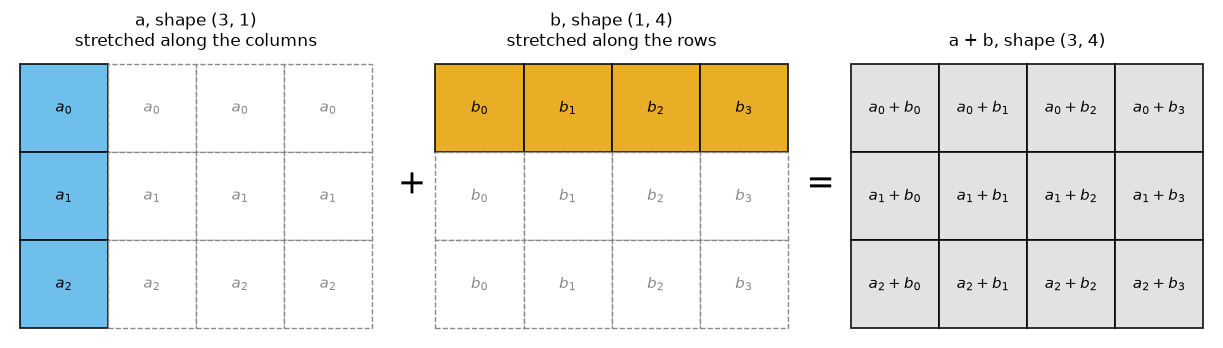

In [13]:
# Figure 2.1 — the shape rule in pictures
def figure_2_1():
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle

    def grid(ax, rows, cols, real_rows, real_cols, color, label_fn, title):
        """Draw a rows x cols grid; cells outside the real_rows x real_cols block are 'virtual' copies."""
        for i in range(rows):
            for j in range(cols):
                real = (i < real_rows) and (j < real_cols)
                ax.add_patch(Rectangle((j, -i - 1), 1, 1, facecolor=color if real else "white",
                                       alpha=0.85 if real else 1.0,
                                       edgecolor="black" if real else "#888888",
                                       linestyle="-" if real else "--", linewidth=1.2 if real else 0.9))
                ax.text(j + 0.5, -i - 0.5, label_fn(i, j), ha="center", va="center",
                        fontsize=10, color="black" if real else "#888888")
        ax.set_xlim(-0.1, cols + 0.1); ax.set_ylim(-rows - 0.1, 0.1)
        ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=11)

    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.1), gridspec_kw={"width_ratios": [1, 1, 1]})
    grid(axes[0], 3, 4, 3, 1, SKY,    lambda i, j: f"$a_{i}$", "a, shape (3, 1)\nstretched along the columns")
    grid(axes[1], 3, 4, 1, 4, ORANGE, lambda i, j: f"$b_{j}$", "b, shape (1, 4)\nstretched along the rows")
    grid(axes[2], 3, 4, 3, 4, "#DDDDDD", lambda i, j: f"$a_{i}+b_{j}$", "a + b, shape (3, 4)")
    fig.text(0.342, 0.5, "+", fontsize=22, ha="center", va="center")
    fig.text(0.665, 0.5, "=", fontsize=22, ha="center", va="center")
    fig.tight_layout()
    plt.show()

figure_2_1()

Solid cells hold real data, dashed cells are the "virtual" copies that NumPy pretends to have. No memory is allocated for them. Broadcasting is what makes the most common operations of this book one-liners. For example, **standardizing the columns** of a data matrix subtracts a vector of shape `(d,)` from each of the `n` rows:

In [14]:
X_centered = X_iris - X_iris.mean(axis=0)               # (150, 4) - (4,)   -> (150, 4)
X_standard = X_centered / X_iris.std(axis=0)            # (150, 4) / (4,)   -> (150, 4)

print("column means after standardizing:", X_standard.mean(axis=0).round(12))
print("column stds  after standardizing:", X_standard.std(axis=0).round(12))

column means after standardizing: [-0. -0. -0. -0.]
column stds  after standardizing: [1. 1. 1. 1.]


### Worked example 2.1 — all pairwise distances without a loop

Many methods (k-nearest neighbors in Chapter 4, kernels in Chapter 9, clustering in Chapter 12) need the squared distance $D^2_{ij} = \lVert \mathbf{x}_i - \mathbf{x}_j\rVert_2^2$ between *all pairs* of samples. Take three points in the plane, stored as the rows of

$$
\mathbf{P} = \begin{pmatrix} 0 & 0 \\ 3 & 4 \\ 6 & 0 \end{pmatrix}.
$$

**By hand.** $D^2_{01} = 3^2 + 4^2 = 25$, $D^2_{02} = 6^2 = 36$, $D^2_{12} = 3^2 + 4^2 = 25$, and the diagonal is zero.

**With broadcasting.** Insert axes so that `P[:, None, :]` has shape `(3, 1, 2)` and `P[None, :, :]` has shape `(1, 3, 2)`. Their difference has shape `(3, 3, 2)` and contains $\mathbf{x}_i - \mathbf{x}_j$ at position $[i, j, :]$. Squaring and summing over the last axis gives $D^2$.

**With algebra.** Expanding the square gives $\lVert \mathbf{x}_i - \mathbf{x}_j\rVert^2 = \lVert \mathbf{x}_i\rVert^2 + \lVert \mathbf{x}_j\rVert^2 - 2\,\mathbf{x}_i^\top\mathbf{x}_j$. The last term is the entry $(i, j)$ of the **Gram matrix** $\mathbf{P}\mathbf{P}^\top$, so $D^2 = \mathbf{n}\mathbf{1}^\top + \mathbf{1}\mathbf{n}^\top - 2\mathbf{P}\mathbf{P}^\top$ with $\mathbf{n}$ the vector of squared norms. This version never builds the `(n, n, d)` array, which matters for large data sets.

In [15]:
P = np.array([[0., 0.], [3., 4.], [6., 0.]])

# (1) broadcasting
D2_broadcast = ((P[:, None, :] - P[None, :, :]) ** 2).sum(axis=-1)
print("broadcasting:\n", D2_broadcast)

# (2) the Gram-matrix identity
norms = (P ** 2).sum(axis=1)                              # vector n, shape (3,)
D2_gram = norms[:, None] + norms[None, :] - 2 * P @ P.T
print("Gram identity equals broadcasting:", np.allclose(D2_gram, D2_broadcast))

# The same two methods on the 150 Iris flowers (an (150, 150) matrix), compared with SciPy
from scipy.spatial.distance import cdist

D2_iris_b = ((X_iris[:, None, :] - X_iris[None, :, :]) ** 2).sum(axis=-1)
n2 = (X_iris ** 2).sum(axis=1)
D2_iris_g = n2[:, None] + n2[None, :] - 2 * X_iris @ X_iris.T
dist_scipy = cdist(X_iris, X_iris)

print("\nIris, squared distances: Gram identity agrees with broadcasting:", np.allclose(D2_iris_g, D2_iris_b))
print("Iris, distances: broadcasting agrees with SciPy                :", np.allclose(np.sqrt(D2_iris_b), dist_scipy))
print("smallest entry of the Gram version of D^2:", D2_iris_g.min(), " (a squared distance cannot be negative!)")
dist_gram = np.sqrt(np.maximum(D2_iris_g, 0))          # clip the tiny negative values before the square root
print("largest error of the Gram version on the distances:", np.abs(dist_gram - dist_scipy).max())

broadcasting:
 [[ 0. 25. 36.]
 [25.  0. 25.]
 [36. 25.  0.]]
Gram identity equals broadcasting: True

Iris, squared distances: Gram identity agrees with broadcasting: True
Iris, distances: broadcasting agrees with SciPy                : True
smallest entry of the Gram version of D^2: -5.684341886080802e-14  (a squared distance cannot be negative!)
largest error of the Gram version on the distances: 1.6858739404357614e-07


The two methods agree, and the broadcasting version agrees with SciPy. But look at the last two lines. The Gram identity returned a tiny **negative** number (about $-6\times 10^{-14}$) even though a squared distance cannot be negative: it is a rounding error, produced when two nearly equal numbers are subtracted. That is why the code clips with `np.maximum(D2, 0)` before taking the square root, and even then the square root *amplifies* the error: an error of $10^{-14}$ in $D^2$ becomes an error of about $10^{-7}$ in a distance that should be zero. This is harmless for most purposes, and it is the first example of a numerical trap. We will see more in Section 2.3.8.

:::{admonition} Pitfall
:class: warning
**The silent `(n,) - (n, 1)` bug.** Suppose `y` has shape `(n,)` (a vector of targets) and `y_hat` has shape `(n, 1)` (a column of predictions, as many libraries return). Then `y - y_hat` does not raise any error: by the broadcasting rule it has shape `(n, n)`, and the "mean squared error" computed from it is wrong.
:::

In [16]:
y_true = np.array([1.0, 2.0, 3.0, 4.0])
y_pred = np.array([[1.5], [2.5], [2.5], [4.5]])           # shape (4, 1)

wrong = np.mean((y_true - y_pred) ** 2)                    # broadcasts to (4, 4)!
right = np.mean((y_true - y_pred.ravel()) ** 2)            # both of shape (4,)
print("shape of y_true - y_pred:", (y_true - y_pred).shape)
print(f"wrong MSE = {wrong:.3f}   right MSE = {right:.3f}")

shape of y_true - y_pred: (4, 4)
wrong MSE = 2.500   right MSE = 0.250


**Habit:** when a result looks plausible but is not what you expected, `print(a.shape)` for every operand. Better, add `assert y_true.shape == y_pred.shape` in the code that matters.

### 2.3.7 Linear algebra with `numpy.linalg`

Matrix operations use the operator `@` (matrix product), `.T` (transpose), and the submodule `np.linalg`. The ones used in this book are collected in the table.

| Task | Code | Chapter where it is used |
|---|---|---|
| matrix product, dot product | `A @ B`, `u @ v` | everywhere |
| norms | `np.linalg.norm(v)` (2-norm), `np.linalg.norm(v, 1)` ($\ell_1$) | 4, 6, 10 |
| solve $\mathbf{A}\mathbf{x} = \mathbf{b}$ | `np.linalg.solve(A, b)` | 1, 6 |
| least squares | `np.linalg.lstsq(A, b, rcond=None)` | 1, 6 |
| eigenvalues of a symmetric matrix | `np.linalg.eigh(S)` | 2, 13 |
| singular value decomposition | `np.linalg.svd(X)` | 13 |
| rank, condition number | `np.linalg.matrix_rank(A)`, `np.linalg.cond(A)` | 1, 6 |

Two rules of good practice. **Do not compute the inverse** to solve a system: `np.linalg.solve(A, b)` is faster and more accurate than `np.linalg.inv(A) @ b`. And **use `eigh` (not `eig`) for symmetric matrices**: it is faster, returns real eigenvalues sorted in increasing order, and the eigenvectors are orthonormal.

### Worked example 2.2 — an eigendecomposition by hand and by code

Eigenvalues and eigenvectors of a symmetric matrix will come back many times (covariance matrices in Section 2.6, principal components in Chapter 13). Consider
$$
\mathbf{A} = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}.
$$

**By hand.** The eigenvalues solve $\det(\mathbf{A} - \lambda\mathbf{I}) = (2 - \lambda)^2 - 1 = 0$, that is $\lambda = 3$ and $\lambda = 1$. For $\lambda = 3$ we need $(\mathbf{A} - 3\mathbf{I})\mathbf{v} = \mathbf{0}$, that is $-v_1 + v_2 = 0$, so $\mathbf{v}_1 = \tfrac{1}{\sqrt 2}(1, 1)^\top$. For $\lambda = 1$ we get $\mathbf{v}_2 = \tfrac{1}{\sqrt 2}(1, -1)^\top$. Eigenvectors are defined up to a sign. Stacking them as columns of $\mathbf{Q}$ and the eigenvalues on the diagonal of $\boldsymbol{\Lambda}$,
$$
\mathbf{A} = \mathbf{Q}\boldsymbol{\Lambda}\mathbf{Q}^\top, \qquad \mathbf{Q}^\top\mathbf{Q} = \mathbf{I}.
$$
Geometrically, $\mathbf{A}$ stretches the plane by a factor 3 along the diagonal direction $(1, 1)$ and leaves the direction $(1, -1)$ unchanged.

In [17]:
A = np.array([[2., 1.], [1., 2.]])
eigenvalues, Q = np.linalg.eigh(A)            # eigenvalues in increasing order
print("eigenvalues:", eigenvalues)
print("Q (columns are eigenvectors):\n", Q.round(4))
print("Q^T Q = I      :", np.allclose(Q.T @ Q, np.eye(2)))
print("Q diag(l) Q^T  :", np.allclose(Q @ np.diag(eigenvalues) @ Q.T, A))
print("A v = lambda v :", np.allclose(A @ Q, Q * eigenvalues))   # each column of Q scaled by its eigenvalue

eigenvalues: [1. 3.]
Q (columns are eigenvectors):
 [[-0.7071  0.7071]
 [ 0.7071  0.7071]]
Q^T Q = I      : True
Q diag(l) Q^T  : True
A v = lambda v : True


`eigh` returns the eigenvalues in increasing order, $1$ and $3$, and eigenvectors that agree with the hand computation up to a sign.

### 2.3.8 Numerical traps: computers do not do real arithmetic

Floating-point numbers (`float64`) have about 16 significant decimal digits, and every operation rounds. Most of the time this is invisible; sometimes it is not. Four traps, with a demonstration of each.

In [18]:
# Trap 1: equality of floats
print("0.1 + 0.2 == 0.3          :", 0.1 + 0.2 == 0.3, "  (0.1 + 0.2 =", 0.1 + 0.2, ")")
print("np.isclose(0.1 + 0.2, 0.3):", np.isclose(0.1 + 0.2, 0.3))

# Trap 2: adding numbers of very different size
print("\n1e16 + 1 == 1e16          :", 1e16 + 1 == 1e16, "  (the 1 is lost)")
print("machine epsilon float64   :", np.finfo(np.float64).eps, "| float32:", np.finfo(np.float32).eps)

# Trap 3: catastrophic cancellation in the variance formula E[x^2] - (E[x])^2
x = 1e9 + np.random.default_rng(SEED).normal(size=100_000)    # true variance is 1
naive = np.mean(x ** 2) - np.mean(x) ** 2
print(f"\nnaive variance  : {naive}")
print(f"np.var          : {np.var(x):.4f}   (the true value is close to 1)")

# Trap 4: overflow in the exponential (softmax and likelihoods appear in later chapters)
z = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(all="ignore"):                    # silence the warnings, just for this demo
    softmax_naive = np.exp(z) / np.exp(z).sum()
shifted = z - z.max()                              # subtracting a constant does not change the ratio
softmax_stable = np.exp(shifted) / np.exp(shifted).sum()
print("\nnaive softmax  :", softmax_naive)
print("stable softmax :", softmax_stable.round(4))

0.1 + 0.2 == 0.3          : False   (0.1 + 0.2 = 0.30000000000000004 )
np.isclose(0.1 + 0.2, 0.3): True

1e16 + 1 == 1e16          : True   (the 1 is lost)
machine epsilon float64   : 2.220446049250313e-16 | float32: 1.1920929e-07

naive variance  : -384.0
np.var          : 1.0074   (the true value is close to 1)

naive softmax  : [nan nan nan]
stable softmax : [0.09   0.2447 0.6652]


What to remember:

1. **Never compare floats with `==`.** Use `np.isclose` or `np.allclose` (relative and absolute tolerances).
2. **Subtracting two nearly equal large numbers destroys precision** (cancellation). Use the library's stable implementation (`np.var`, which subtracts the mean first) instead of a textbook formula.
3. **Overflow and underflow are real**: $e^{1000}$ is `inf`, and a product of many small probabilities becomes 0. The remedies are to *subtract the maximum* before exponentiating (the "log-sum-exp trick", used by every softmax implementation) and to work with **log-probabilities** instead of probabilities.
4. **A different order of operations gives a different last digit.** Do not expect two correct implementations to agree to the last bit; test with tolerances.

These issues explain many strange `nan` and `inf` values in training logs, and we will meet them again in Chapters 6 and 15.

## 2.4 pandas: tables with labels

NumPy arrays hold numbers and nothing else: no column names, no mixed types, no notion of a missing value. Real data sets have all of these, and **pandas** is the standard library for them. Its two main objects are the **Series** (a labeled one-dimensional array, one column) and the **DataFrame** (a table of Series that share the same row labels, the *index*).

A good division of labor is: **use pandas to explore, clean, and prepare data, and NumPy arrays (or scikit-learn's transformers) to model.** scikit-learn accepts DataFrames directly, and `df.to_numpy()` gives the underlying array whenever you need it.

We work with the **Wine** data set: 178 wines grown in the same region of Italy, from three different cultivars (the classes), described by 13 chemical measurements.

In [19]:
from sklearn.datasets import load_wine

wine = load_wine(as_frame=True)
df = wine.frame                       # a DataFrame: 13 feature columns plus the column 'target'
print(type(df).__name__, "with shape", df.shape)
df.head()

DataFrame with shape (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [20]:
df.info()                             # column names, types, and number of non-missing values

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [21]:
df.describe().T.round(2)              # summary statistics of every column (transposed: one row per column)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


`info()` tells us that there are 178 rows, that all 14 columns are complete (no missing values), and that the types are numeric. `describe()` gives, for each column, the count, mean, standard deviation, minimum, quartiles, and maximum. Look at the `std` column: `proline` has a standard deviation of about 315, while `hue` has 0.23. Keep that in mind: we come back to it in Section 2.7.

### 2.4.1 Selecting rows and columns

There are four ways to select, and it is worth knowing all of them.

| You want | Code | Note |
|---|---|---|
| one column (a Series) | `df["alcohol"]` | |
| several columns (a DataFrame) | `df[["alcohol", "proline"]]` | note the double brackets |
| rows and columns by **label** | `df.loc[0:2, "alcohol":"magnesium"]` | the end label is **included** |
| rows and columns by **position** | `df.iloc[0:3, 0:3]` | the end is excluded, as in NumPy |
| rows satisfying a condition | `df[df["proline"] > 1000]` | a Boolean mask, as in NumPy |

In [22]:
print("one column:", type(df["alcohol"]).__name__, df["alcohol"].shape)
print("\nloc (labels, end included):")
print(df.loc[0:2, "alcohol":"magnesium"])
print("\niloc (positions, end excluded):")
print(df.iloc[0:2, 0:3])

# Boolean conditions: combine with & (and), | (or), ~ (not), with parentheses
strong = df[(df["proline"] > 1000) & (df["alcohol"] > 13.5)]
print("\nwines with proline > 1000 and alcohol > 13.5:", len(strong))
print("their classes:", strong["target"].value_counts().to_dict())

# The same selection written as a query string
print("with query():", len(df.query("proline > 1000 and alcohol > 13.5")))

one column: Series (178,)

loc (labels, end included):
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium
0    14.23        1.71  2.43               15.6      127.0
1    13.20        1.78  2.14               11.2      100.0
2    13.16        2.36  2.67               18.6      101.0

iloc (positions, end excluded):
   alcohol  malic_acid   ash
0    14.23        1.71  2.43
1    13.20        1.78  2.14

wines with proline > 1000 and alcohol > 13.5: 33
their classes: {0: 33}
with query(): 33


### 2.4.2 Grouping, new columns, and correlations

The pattern **split, apply, combine** is at the heart of data analysis: split the rows into groups, compute something for each group, and collect the results. In pandas it is `groupby`.

In [23]:
print("samples per class:", df["target"].value_counts().sort_index().to_dict())

# Mean and standard deviation of three features, class by class
summary = df.groupby("target")[["alcohol", "flavanoids", "proline"]].agg(["mean", "std"]).round(2)
print(summary)

# A new column is created by a vectorized formula on existing columns
df_ext = df.assign(phenol_ratio=df["flavanoids"] / df["total_phenols"])
print("\nmean phenol_ratio by class:", df_ext.groupby("target")["phenol_ratio"].mean().round(3).to_dict())

# Pearson correlation of every feature with 'flavanoids'
corr_flav = df.drop(columns="target").corr()["flavanoids"].drop("flavanoids").sort_values(ascending=False)
print("\nfeatures most correlated with flavanoids:")
print(corr_flav.head(3).round(3))

samples per class: {0: 59, 1: 71, 2: 48}
       alcohol       flavanoids        proline        
          mean   std       mean   std     mean     std
target                                                
0        13.74  0.46       2.98  0.40  1115.71  221.52
1        12.28  0.54       2.08  0.71   519.51  157.21
2        13.15  0.53       0.78  0.29   629.90  115.10

mean phenol_ratio by class: {0: 1.051, 1: 0.919, 2: 0.478}

features most correlated with flavanoids:
total_phenols                   0.865
od280/od315_of_diluted_wines    0.787
proanthocyanins                 0.653
Name: flavanoids, dtype: float64


The summary shows that the three classes differ a lot in `proline` (class 0 has the highest mean, around 1116) and in `flavanoids` (class 2 has the lowest). These are the kind of observations that a first exploration should produce, and that will later explain why a classifier works well on this data set.

### 2.4.3 Two pandas habits worth acquiring

**Alignment by label.** Arithmetic between pandas objects matches the *labels*, not the positions. This is powerful, and it can produce `NaN` (the marker of a missing value) when the labels do not match:

In [24]:
s1 = pd.Series([1, 2, 3], index=["a", "b", "c"])
s2 = pd.Series([10, 20, 30], index=["b", "c", "d"])
print(s1 + s2)                       # 'a' and 'd' appear in only one of the two Series

a     NaN
b    12.0
c    23.0
d     NaN
dtype: float64


:::{admonition} Pitfall
:class: warning
**Do not assign through a chained selection.** An expression such as `df[df["alcohol"] > 14]["alcohol"] = 0` first creates a temporary object and then modifies *that*, not `df`. In recent versions of pandas this never changes the original, and in older ones it sometimes did, which was worse. The reliable way is a single `.loc` call: `df.loc[df["alcohol"] > 14, "alcohol"] = 0`. And when you want an independent table, call `.copy()`.
:::

**From pandas to NumPy.** Models expect arrays of numbers. `X = df.drop(columns="target").to_numpy()` produces the data matrix `X` of shape `(178, 13)` and `y = df["target"].to_numpy()` the vector of labels. Keep the column names in a list (`list(df.columns)`) if you need them later, for example to label a plot or to interpret the weights of a linear model.

## 2.5 Matplotlib: drawing figures that tell the truth

**Matplotlib** is the plotting library behind almost every figure of this book. It has two interfaces. The "state machine" interface (`plt.plot(...)`, `plt.title(...)`) is quick but becomes confusing as soon as there is more than one panel. The **object-oriented** interface is explicit, and we use it exclusively:

- a **Figure** is the whole canvas;
- an **Axes** is one panel, with its own coordinates, labels, and title;
- `fig, ax = plt.subplots()` creates both, and `fig, axes = plt.subplots(2, 2)` creates a grid of panels (`axes` is then an array of Axes);
- everything you draw is a method of an Axes: `ax.plot`, `ax.scatter`, `ax.hist`, `ax.set_xlabel`, `ax.legend`.

The cell below shows the typical structure of a figure: create, draw, decorate, show.

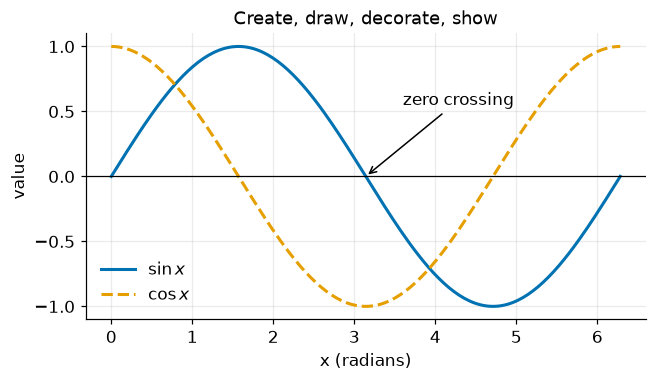

In [25]:
x = np.linspace(0, 2 * np.pi, 200)

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(x, np.sin(x), color=BLUE, linewidth=2, label=r"$\sin x$")                       # draw
ax.plot(x, np.cos(x), color=ORANGE, linewidth=2, linestyle="--", label=r"$\cos x$")     # a second encoding: dashes
ax.axhline(0, color="black", linewidth=0.8)
ax.annotate("zero crossing", xy=(np.pi, 0), xytext=(3.6, 0.55),
            arrowprops={"arrowstyle": "->"})                                             # annotate
ax.set_xlabel("x (radians)")                                                             # decorate
ax.set_ylabel("value")
ax.set_title("Create, draw, decorate, show")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Figure 2.2 — four views of the same data set

Different questions call for different plots. Here are four standard ones, drawn on the Wine data: a **histogram** (how is one variable distributed, class by class?), a **scatter plot** (how do two variables relate?), a **box plot** (how do the quartiles and the extreme values of a variable compare across groups?), and a **correlation heat map** (which features move together?). Colors follow the Okabe-Ito palette, and the classes also differ by marker shape, so the figure survives a black-and-white print.

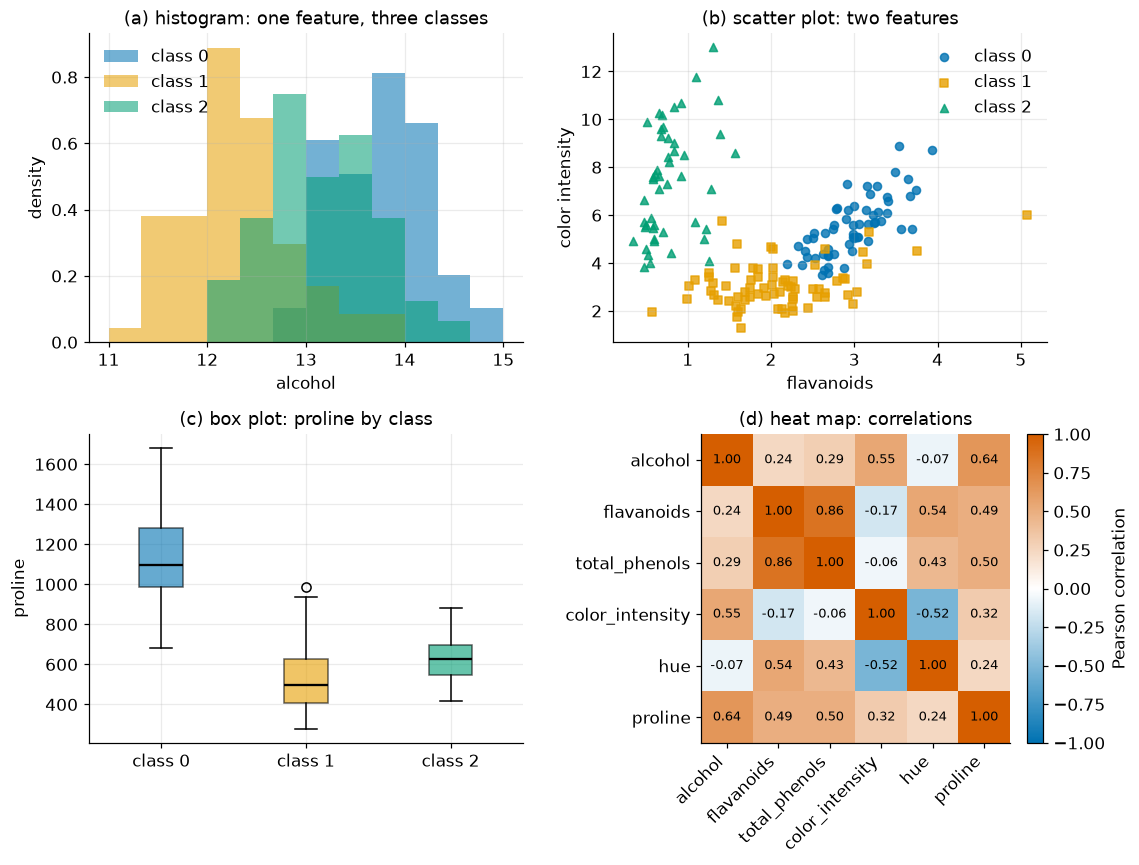

In [26]:
# Figure 2.2 — a gallery of four basic plots on the Wine data
def figure_2_2():
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap
    from sklearn.datasets import load_wine

    data = load_wine(as_frame=True).frame
    colors, markers = [BLUE, ORANGE, GREEN], ["o", "s", "^"]
    names = ["class 0", "class 1", "class 2"]

    fig, axes = plt.subplots(2, 2, figsize=(10.5, 8))

    # (a) histograms of one feature, class by class
    ax = axes[0, 0]
    for k in range(3):
        ax.hist(data.loc[data["target"] == k, "alcohol"], bins=12, range=(11, 15), density=True,
                color=colors[k], alpha=0.55, label=names[k])
    ax.set(xlabel="alcohol", ylabel="density", title="(a) histogram: one feature, three classes")
    ax.legend(frameon=False)

    # (b) scatter plot of two features
    ax = axes[0, 1]
    for k in range(3):
        sel = data["target"] == k
        ax.scatter(data.loc[sel, "flavanoids"], data.loc[sel, "color_intensity"], s=28,
                   color=colors[k], marker=markers[k], alpha=0.8, label=names[k])
    ax.set(xlabel="flavanoids", ylabel="color intensity", title="(b) scatter plot: two features")
    ax.legend(frameon=False)

    # (c) box plot: median, quartiles, and extreme values
    ax = axes[1, 0]
    boxes = ax.boxplot([data.loc[data["target"] == k, "proline"] for k in range(3)], patch_artist=True,
                       tick_labels=names, medianprops={"color": "black", "linewidth": 1.5})
    for patch, color in zip(boxes["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.6)
    ax.set(ylabel="proline", title="(c) box plot: proline by class")

    # (d) correlation heat map with a blue-white-vermilion diverging colormap centered at 0
    ax = axes[1, 1]
    cols = ["alcohol", "flavanoids", "total_phenols", "color_intensity", "hue", "proline"]
    corr = data[cols].corr().to_numpy()
    cmap = LinearSegmentedColormap.from_list("bwv", [BLUE, "white", VERMILION])
    im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=8.5)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
    ax.set_title("(d) heat map: correlations")

    fig.tight_layout()
    plt.show()

figure_2_2()

What do we read? (a) The alcohol content of class 0 is higher than that of class 1, and the three histograms overlap: alcohol alone does not separate the classes. (b) In the plane of `flavanoids` and `color_intensity` the three classes form three groups that overlap only a little, so a simple classifier should do well here. (c) `proline` has a much larger scale than the other features, class 0 sits far above the others, and class 1 has one high outlier (the circle above its box). (d) `flavanoids` and `total_phenols` are strongly correlated (0.86): they carry similar information, which will matter for linear models in Chapter 6.

### A checklist for honest figures

1. **Label axes, with units** when you know them, and give every figure a title or a caption that says what it shows.
2. **One message per panel.** If you need a paragraph to explain a figure, split it.
3. **Do not rely on color alone.** Vary the marker, the line style, or add direct labels. About 1 man in 12 has a color-vision deficiency.
4. **Use sequential colormaps for magnitudes and diverging ones for signed quantities** centered at the neutral value (as in panel d). Avoid the rainbow colormap `jet`: it creates false boundaries.
5. **Start bar charts at zero**; for scatter and line plots you may zoom, but say so. Use a log scale (`ax.set_yscale("log")`) when values span several orders of magnitude, and say so on the axis.
6. **Show the spread, not only the mean**: error bars, quantile bands, or the raw points.
7. **Save at the right quality**: `fig.savefig("name.pdf")` gives a vector figure for papers, `fig.savefig("name.png", dpi=300)` a high-resolution bitmap.

:::{admonition} Try it
:class: note
Change the feature in panel (a) to `proline` or `flavanoids` and re-run the cell: which feature separates the classes best in a single histogram? Then replace the scatter pair with two features of your choice. A minute of exploration like this is how real data analyses begin.
:::

## 2.6 Probability: the language of uncertainty

Why does a book on machine learning need probability? Because data are **noisy samples** from a world we do not control. In Chapter 1 we wrote that the training pairs $(\mathbf{x}_i, y_i)$ are drawn from an unknown distribution $\mathcal{D}$, that the test error estimates an *expected* loss, and that the same model can look good or bad depending on which data we happened to see. Probability gives these statements a precise meaning. In this section we collect the small number of ideas that the rest of the book uses, each one tied to a computation you can run.

### 2.6.1 Events, conditional probability, and Bayes' rule

An **event** $A$ is something that may or may not happen, and its probability $\mathbb{P}(A)$ is a number in $[0, 1]$ with three basic rules: the probability of a certain event is 1; for events that cannot happen together, $\mathbb{P}(A \cup B) = \mathbb{P}(A) + \mathbb{P}(B)$; and the probability of "not $A$" is $1 - \mathbb{P}(A)$. The **conditional probability** of $A$ given that $B$ has occurred is
$$
\mathbb{P}(A \mid B) = \frac{\mathbb{P}(A \cap B)}{\mathbb{P}(B)}, \qquad \mathbb{P}(B) > 0.
$$
Two events are **independent** if knowing one tells us nothing about the other: $\mathbb{P}(A \cap B) = \mathbb{P}(A)\,\mathbb{P}(B)$, equivalently $\mathbb{P}(A \mid B) = \mathbb{P}(A)$. If $A_1, \dots, A_m$ are mutually exclusive events that cover all possibilities, then the **law of total probability** says
$$
\mathbb{P}(B) = \sum_{j=1}^{m} \mathbb{P}(B \mid A_j)\,\mathbb{P}(A_j).
$$
Writing $\mathbb{P}(A \cap B)$ in two ways, as $\mathbb{P}(A\mid B)\mathbb{P}(B)$ and as $\mathbb{P}(B\mid A)\mathbb{P}(A)$, gives **Bayes' rule**:
$$
\boxed{\;\mathbb{P}(A \mid B) = \frac{\mathbb{P}(B \mid A)\,\mathbb{P}(A)}{\mathbb{P}(B)}\;}
$$
Read $\mathbb{P}(A)$ as the **prior** (what we believed before seeing $B$), $\mathbb{P}(B \mid A)$ as the **likelihood** (how probable the evidence is if $A$ is true), and $\mathbb{P}(A\mid B)$ as the **posterior** (our updated belief). Bayes' rule is the template of every classifier that outputs probabilities: given the features $\mathbf{x}$, what is $\mathbb{P}(y \mid \mathbf{x})$?

### Worked example 2.3 — what does a positive test mean?

A screening test for a disease has these (illustrative) characteristics: the disease affects 1% of the population (the *prevalence*); the test is positive for 90% of the sick people (the *sensitivity*); and it is negative for 95% of the healthy ones (the *specificity*, so 5% of healthy people get a false positive). A person tests positive. What is the probability that the person is sick?

**By hand.** Let $D$ = "sick" and $+$ = "positive test". Then $\mathbb{P}(D) = 0.01$, $\mathbb{P}(+\mid D) = 0.90$, $\mathbb{P}(+ \mid \bar D) = 0.05$. By total probability,
$$
\mathbb{P}(+) = 0.90 \cdot 0.01 + 0.05 \cdot 0.99 = 0.0090 + 0.0495 = 0.0585,
$$
and by Bayes' rule
$$
\mathbb{P}(D \mid +) = \frac{0.90 \cdot 0.01}{0.0585} = \frac{0.0090}{0.0585} \approx 0.154.
$$
Only about **15%** of the positive results come from sick people, even though the test is "90% accurate". The reason is the low prior: sick people are rare, so false positives from the large healthy majority outnumber true positives. **Natural frequencies** make this vivid: in 10,000 people, 100 are sick and 90 of them test positive; of the 9,900 healthy people, 495 test positive; so 90 of the $90 + 495 = 585$ positives are sick.

In [27]:
prevalence, sensitivity, specificity = 0.01, 0.90, 0.95

# Exact computation with Bayes' rule
p_pos = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
posterior = sensitivity * prevalence / p_pos
print(f"P(positive) = {p_pos:.4f} | P(sick | positive) = {posterior:.4f}")

# Natural frequencies in 10,000 people
sick = 10_000 * prevalence
print("sick:", sick, "| true positives:", sick * sensitivity,
      "| false positives:", (10_000 - sick) * (1 - specificity))

# Check by simulation: one million people
rng = np.random.default_rng(SEED)
N = 1_000_000
is_sick = rng.random(N) < prevalence
positive = np.where(is_sick, rng.random(N) < sensitivity, rng.random(N) >= specificity)
print(f"simulation: P(positive) = {positive.mean():.4f} | P(sick | positive) = {is_sick[positive].mean():.4f}")

P(positive) = 0.0585 | P(sick | positive) = 0.1538
sick: 100.0 | true positives: 90.0 | false positives: 495.00000000000045
simulation: P(positive) = 0.0584 | P(sick | positive) = 0.1541


The simulation agrees with the formula, up to random fluctuations of the order of $1/\sqrt{N}$. This example is not a curiosity. In machine learning, a classifier with 95% accuracy can be useless on a rare class, which is why Chapter 5 introduces precision, recall, and ROC curves: they take the base rates into account.

### 2.6.2 Random variables, expectation, and variance

A **random variable** $X$ is a number whose value is determined by chance: the result of a die, the height of a randomly chosen person, the squared error of a model on a randomly chosen test sample. A *discrete* random variable takes values $x$ with probabilities given by its **probability mass function** $p(x) = \mathbb{P}(X = x)$. A *continuous* one has a **probability density function** (PDF) $f(x) \ge 0$, with $\mathbb{P}(a \le X \le b) = \int_a^b f(x)\,dx$ and $\int f = 1$. In both cases the **cumulative distribution function** (CDF) is $F(x) = \mathbb{P}(X \le x)$.

The **expectation** (mean) of $X$ is its average value over many repetitions,
$$
\mathbb{E}[X] = \sum_x x\,p(x) \quad\text{(discrete)}, \qquad \mathbb{E}[X] = \int x\,f(x)\,dx \quad\text{(continuous)},
$$
and for a function $g$, $\mathbb{E}[g(X)]$ is defined in the same way with $g(x)$ in place of $x$. Expectation is **linear**, always, even when the variables are dependent:
$$
\mathbb{E}[aX + bY + c] = a\,\mathbb{E}[X] + b\,\mathbb{E}[Y] + c.
$$
The **variance** measures the spread around the mean, and the **standard deviation** is its square root:
$$
\operatorname{Var}(X) = \mathbb{E}\big[(X - \mu)^2\big], \quad \mu = \mathbb{E}[X], \qquad \sigma = \sqrt{\operatorname{Var}(X)}.
$$
Expanding the square and using linearity gives a useful identity (and, as we saw in Section 2.3.8, a numerically dangerous formula):
$$
\operatorname{Var}(X) = \mathbb{E}[X^2 - 2\mu X + \mu^2] = \mathbb{E}[X^2] - 2\mu\,\mathbb{E}[X] + \mu^2 = \mathbb{E}[X^2] - \mu^2.
$$
It follows that $\operatorname{Var}(aX + b) = a^2 \operatorname{Var}(X)$: shifting does not change the spread, scaling by $a$ multiplies the variance by $a^2$. For **independent** $X$ and $Y$, $\operatorname{Var}(X + Y) = \operatorname{Var}(X) + \operatorname{Var}(Y)$.

:::{admonition} Key idea
:class: tip
**The risk of Chapter 1 is an expectation.** The expected risk is $R(f) = \mathbb{E}\big[\ell(y, f(\mathbf{x}))\big]$ and the empirical risk is the *sample mean* of the same loss over the $n$ training examples. How close the sample mean is to the expectation is exactly what the law of large numbers (Section 2.6.6) and, in Chapter 3, the theory of generalization are about.
:::

### Worked example 2.4 — a fair die

Let $X$ be the result of a fair six-sided die, $p(x) = 1/6$ for $x = 1, \dots, 6$. Then
$$
\mathbb{E}[X] = \frac{1 + 2 + \dots + 6}{6} = 3.5, \qquad
\mathbb{E}[X^2] = \frac{1 + 4 + 9 + 16 + 25 + 36}{6} = \frac{91}{6}, \qquad
\operatorname{Var}(X) = \frac{91}{6} - \Big(\frac{7}{2}\Big)^2 = \frac{35}{12} \approx 2.917.
$$
For the sum $S$ of two independent dice, linearity and independence give $\mathbb{E}[S] = 7$ and $\operatorname{Var}(S) = 35/6 \approx 5.833$. We check with the definitions and with a simulation.

In [28]:
faces = np.arange(1, 7)
pmf = np.full(6, 1 / 6)
mean = (faces * pmf).sum()
var = ((faces - mean) ** 2 * pmf).sum()
print(f"exact: E[X] = {mean:.4f}, Var(X) = {var:.4f}  (35/12 = {35/12:.4f})")

rolls = np.random.default_rng(SEED).integers(1, 7, size=(1_000_000, 2))
sums = rolls.sum(axis=1)
print(f"simulation of X : mean = {rolls[:, 0].mean():.4f}, variance = {rolls[:, 0].var():.4f}")
print(f"simulation of S : mean = {sums.mean():.4f}, variance = {sums.var():.4f}  (theory: 7 and {35/6:.4f})")

exact: E[X] = 3.5000, Var(X) = 2.9167  (35/12 = 2.9167)
simulation of X : mean = 3.4981, variance = 2.9142
simulation of S : mean = 6.9980, variance = 5.8295  (theory: 7 and 5.8333)


### 2.6.3 Covariance, correlation, and the covariance matrix

For two random variables, the **covariance** measures how they vary together, and the **correlation** is the same quantity made dimensionless:
$$
\operatorname{Cov}(X, Y) = \mathbb{E}\big[(X - \mu_X)(Y - \mu_Y)\big] = \mathbb{E}[XY] - \mu_X \mu_Y, \qquad
\rho_{XY} = \frac{\operatorname{Cov}(X, Y)}{\sigma_X\,\sigma_Y} \in [-1, 1].
$$
A correlation of $\pm 1$ means a perfect linear relationship; 0 means no *linear* relationship. If $X$ and $Y$ are independent, then $\rho = 0$, but the converse is false, as the next cell shows: $Y = X^2$ is completely determined by $X$ and yet uncorrelated with it when $X$ is symmetric around 0.

In [29]:
rng = np.random.default_rng(SEED)
x = rng.normal(size=100_000)
y = x ** 2                                  # y is a deterministic function of x...
print("sample correlation of x and x^2:", np.corrcoef(x, y)[0, 1].round(4))     # ...but the correlation is about 0

sample correlation of x and x^2: -0.0011


Correlation only detects **linear** dependence. This is why a plot (Section 2.5) is always better than a single number.

For a random vector $\mathbf{x} = (x_1, \dots, x_d)^\top$ we collect the means in the **mean vector** $\boldsymbol{\mu} = \mathbb{E}[\mathbf{x}]$ and all the covariances in the **covariance matrix**
$$
\boldsymbol{\Sigma} = \mathbb{E}\big[(\mathbf{x} - \boldsymbol{\mu})(\mathbf{x} - \boldsymbol{\mu})^\top\big], \qquad \Sigma_{ij} = \operatorname{Cov}(x_i, x_j),
$$
so the diagonal contains the variances. $\boldsymbol{\Sigma}$ is **symmetric** and **positive semidefinite**: for every vector $\mathbf{v}$, $\mathbf{v}^\top\boldsymbol{\Sigma}\mathbf{v} = \operatorname{Var}(\mathbf{v}^\top\mathbf{x}) \ge 0$. Hence all its eigenvalues are nonnegative.

From a data matrix $\mathbf{X} \in \mathbb{R}^{n \times d}$, the **sample mean** is $\bar{\mathbf{x}} = \frac{1}{n}\mathbf{X}^\top \mathbf{1}$ (the vector of column means) and, with the centered matrix $\mathbf{X}_c = \mathbf{X} - \mathbf{1}\bar{\mathbf{x}}^\top$ (broadcasting!), the **sample covariance matrix** is
$$
\hat{\boldsymbol{\Sigma}} = \frac{1}{n - 1}\,\mathbf{X}_c^\top \mathbf{X}_c.
$$
The division by $n - 1$ instead of $n$ is explained in Section 2.6.7. We verify it on the 13 features of the Wine data.

In [30]:
X_wine = load_wine().data                   # shape (178, 13)
n_wine = X_wine.shape[0]

Xc = X_wine - X_wine.mean(axis=0)                       # centered data (broadcasting)
Sigma_hat = Xc.T @ Xc / (n_wine - 1)                    # the formula above
print("shape:", Sigma_hat.shape, "| matches np.cov:", np.allclose(Sigma_hat, np.cov(X_wine, rowvar=False)))
print("symmetric:", np.allclose(Sigma_hat, Sigma_hat.T))

eigenvalues = np.linalg.eigvalsh(Sigma_hat)             # ascending order
print(f"eigenvalues: smallest = {eigenvalues.min():.4f}, largest = {eigenvalues.max():.1f}  -> all nonnegative: {(eigenvalues >= 0).all()}")
print("the diagonal contains the variances; the largest is that of proline:",
      Sigma_hat.diagonal().max().round(1), "| the smallest is:", Sigma_hat.diagonal().min().round(4))

shape: (13, 13) | matches np.cov: True
symmetric: True
eigenvalues: smallest = 0.0082, largest = 99201.8  -> all nonnegative: True
the diagonal contains the variances; the largest is that of proline: 99166.7 | the smallest is: 0.0155


`np.cov` expects variables in **rows** by default, so for a data matrix with samples in rows we must pass `rowvar=False` (a common source of bugs, and of $178 \times 178$ matrices when you wanted $13 \times 13$). Note the enormous difference between the largest and smallest variance: that is the scale problem of Section 2.7 again.

Two properties will be used later without further proof. If $\mathbf{z} = \mathbf{A}\mathbf{x} + \mathbf{b}$, then $\mathbb{E}[\mathbf{z}] = \mathbf{A}\boldsymbol{\mu} + \mathbf{b}$ and $\operatorname{Cov}(\mathbf{z}) = \mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top$ (you will prove the second in Exercise 2.5). And, for a data matrix with $n < d$ samples, $\hat{\boldsymbol{\Sigma}}$ is singular, since its rank is at most $n - 1$.

### 2.6.4 A few distributions you need to know

| Distribution | Where | Mass or density | Mean | Variance |
|---|---|---|---|---|
| Bernoulli$(p)$ | one yes/no outcome, $x \in \{0, 1\}$ | $p^x (1-p)^{1-x}$ | $p$ | $p(1-p)$ |
| Binomial$(n, p)$ | number of successes in $n$ independent trials | $\binom{n}{k} p^k (1-p)^{n-k}$ | $np$ | $np(1-p)$ |
| Uniform$(a, b)$ | all values in an interval equally likely | $\frac{1}{b-a}$ on $[a, b]$ | $\frac{a+b}{2}$ | $\frac{(b-a)^2}{12}$ |
| Exponential$(\lambda)$ | waiting times, positive and skewed | $\lambda e^{-\lambda x}$, $x \ge 0$ | $1/\lambda$ | $1/\lambda^2$ |
| Gaussian $\mathcal{N}(\mu, \sigma^2)$ | sums of many small effects; measurement noise | $\frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\big(-\frac{(x-\mu)^2}{2\sigma^2}\big)$ | $\mu$ | $\sigma^2$ |

The **Gaussian** (or normal) distribution deserves special attention. It is the "bell curve", fully described by its mean and variance; it is closed under sums and linear maps; and the central limit theorem (Section 2.6.6) explains why it appears so often. For a Gaussian, about 68% of the probability lies within one standard deviation of the mean, 95% within two, and 99.7% within three. The module `scipy.stats` implements all these distributions with the same interface: `.pdf` (or `.pmf`), `.cdf`, `.ppf` (the inverse of the CDF), `.rvs` (random samples), and `.stats`.

In [31]:
from scipy import stats

z = stats.norm(loc=0, scale=1)               # the standard Gaussian
for k in (1, 2, 3):
    print(f"P(|X - mu| < {k} sigma) = {z.cdf(k) - z.cdf(-k):.4f}")
print("97.5th percentile of N(0,1):", z.ppf(0.975).round(4), "(the familiar 1.96)")

binom = stats.binom(n=10, p=0.3)
mean_b, var_b = binom.stats(moments="mv")
print(f"\nBinomial(10, 0.3): mean = {mean_b:.2f}, variance = {var_b:.2f}  (formulas np = {10 * 0.3:.2f}, np(1-p) = {10 * 0.3 * 0.7:.2f})")
print("P(X = 3) =", binom.pmf(3).round(4), "| P(X <= 3) =", binom.cdf(3).round(4))

P(|X - mu| < 1 sigma) = 0.6827
P(|X - mu| < 2 sigma) = 0.9545
P(|X - mu| < 3 sigma) = 0.9973
97.5th percentile of N(0,1): 1.96 (the familiar 1.96)

Binomial(10, 0.3): mean = 3.00, variance = 2.10  (formulas np = 3.00, np(1-p) = 2.10)
P(X = 3) = 0.2668 | P(X <= 3) = 0.6496


### Figure 2.3 — three views of distributions

(a) The probability mass function of a binomial variable, for two values of $p$. (b) The Gaussian density for three choices of the parameters: $\mu$ moves the curve, $\sigma$ widens it. (c) The CDF of the standard Gaussian, and the **empirical CDF** of a sample of 50 draws: the fraction of the sample that is at most $x$. The empirical CDF is a step function that approaches the true CDF as the sample grows, a first example of data approximating a distribution.

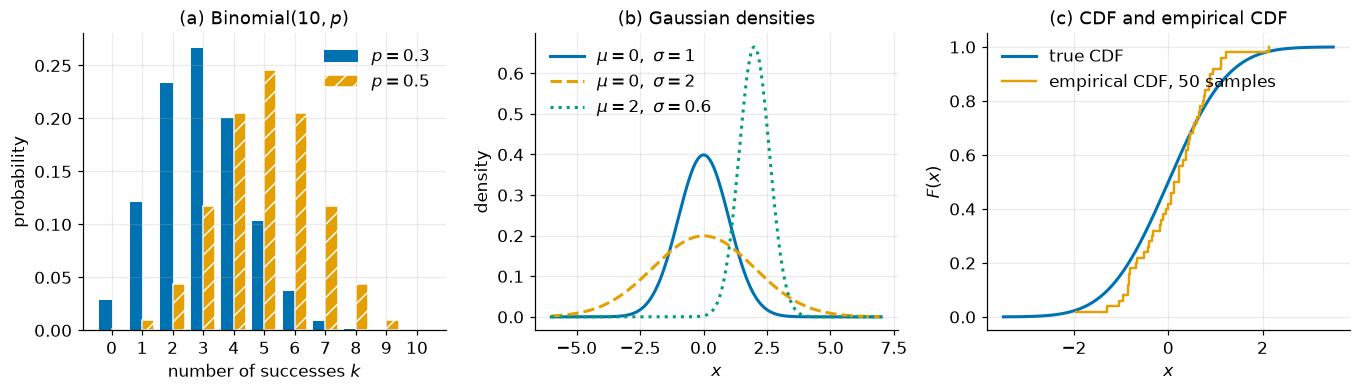

In [32]:
# Figure 2.3 — distributions
def figure_2_3():
    import matplotlib.pyplot as plt
    from scipy import stats

    fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.7))

    ax = axes[0]
    k = np.arange(0, 11)
    ax.bar(k - 0.2, stats.binom.pmf(k, 10, 0.3), width=0.4, color=BLUE, label="$p = 0.3$")
    ax.bar(k + 0.2, stats.binom.pmf(k, 10, 0.5), width=0.4, color=ORANGE, hatch="//", edgecolor="white", label="$p = 0.5$")
    ax.set(xlabel="number of successes $k$", ylabel="probability", title="(a) Binomial$(10, p)$")
    ax.set_xticks(k); ax.legend(frameon=False)

    ax = axes[1]
    x = np.linspace(-6, 7, 600)
    for (mu, sigma), color, ls in zip([(0, 1), (0, 2), (2, 0.6)], [BLUE, ORANGE, GREEN], ["-", "--", ":"]):
        ax.plot(x, stats.norm.pdf(x, mu, sigma), color=color, linestyle=ls, linewidth=2,
                label=rf"$\mu={mu},\ \sigma={sigma}$")
    ax.set(xlabel="$x$", ylabel="density", title="(b) Gaussian densities")
    ax.legend(frameon=False)

    ax = axes[2]
    sample = np.sort(np.random.default_rng(SEED).normal(size=50))
    xs = np.linspace(-3.5, 3.5, 400)
    ax.plot(xs, stats.norm.cdf(xs), color=BLUE, linewidth=2, label="true CDF")
    ax.step(sample, np.arange(1, 51) / 50, where="post", color=ORANGE, linewidth=1.6, label="empirical CDF, 50 samples")
    ax.set(xlabel="$x$", ylabel="$F(x)$", title="(c) CDF and empirical CDF")
    ax.legend(frameon=False, loc="upper left")

    fig.tight_layout()
    plt.show()

figure_2_3()

### 2.6.5 The multivariate Gaussian

For a random vector $\mathbf{x} \in \mathbb{R}^d$ with mean $\boldsymbol{\mu}$ and (invertible) covariance $\boldsymbol{\Sigma}$, the Gaussian density is
$$
f(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}\,\lvert\boldsymbol{\Sigma}\rvert^{1/2}} \exp\!\Big(-\tfrac{1}{2}\,(\mathbf{x} - \boldsymbol{\mu})^\top \boldsymbol{\Sigma}^{-1} (\mathbf{x} - \boldsymbol{\mu})\Big).
$$
The only place where $\mathbf{x}$ appears is the **quadratic form** $(\mathbf{x} - \boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x} - \boldsymbol{\mu})$, the squared **Mahalanobis distance** of $\mathbf{x}$ from the mean. It is a distance that takes the shape of the cloud into account. The level sets of the density are the sets where this quantity is constant, and they are **ellipsoids**. Their geometry follows from the eigendecomposition $\boldsymbol{\Sigma} = \mathbf{Q}\boldsymbol{\Lambda}\mathbf{Q}^\top$ of Worked example 2.2, where $\mathbf{Q}$ contains the orthonormal eigenvectors and $\boldsymbol{\Lambda} = \operatorname{diag}(\lambda_1, \dots, \lambda_d)$:

$$
\boldsymbol{\Sigma}^{-1} = \mathbf{Q}\boldsymbol{\Lambda}^{-1}\mathbf{Q}^\top
\;\;\Longrightarrow\;\;
(\mathbf{x} - \boldsymbol{\mu})^\top\boldsymbol{\Sigma}^{-1}(\mathbf{x} - \boldsymbol{\mu})
= \mathbf{z}^\top \boldsymbol{\Lambda}^{-1}\mathbf{z}
= \sum_{i=1}^{d} \frac{z_i^2}{\lambda_i}, \qquad \mathbf{z} = \mathbf{Q}^\top(\mathbf{x} - \boldsymbol{\mu}).
$$

The vector $\mathbf{z}$ contains the coordinates of $\mathbf{x} - \boldsymbol{\mu}$ in the basis of eigenvectors. So the level set $\sum_i z_i^2/\lambda_i = c^2$ is an ellipsoid **centered at $\boldsymbol{\mu}$**, whose axes point along the **eigenvectors** of $\boldsymbol{\Sigma}$ and whose semi-axis lengths are $c\sqrt{\lambda_i}$. In words: *the eigenvectors of the covariance matrix are the directions of the cloud, and the eigenvalues are the variances along those directions.* This is the geometric idea behind principal component analysis (Chapter 13).

The next figure shows it. The left panel samples from a Gaussian with $\boldsymbol{\mu} = (1, 2)^\top$ and $\boldsymbol{\Sigma} = \begin{pmatrix} 2.5 & 1.5 \\ 1.5 & 2.5 \end{pmatrix}$, whose eigenvalues are 4 and 1 with eigenvectors $\tfrac{1}{\sqrt 2}(1, 1)^\top$ and $\tfrac{1}{\sqrt 2}(1, -1)^\top$. The right panel does the same with real data: the sepal length and width of the 50 *Iris versicolor* flowers, with $\hat{\boldsymbol{\mu}}$ and $\hat{\boldsymbol{\Sigma}}$ estimated from the data.

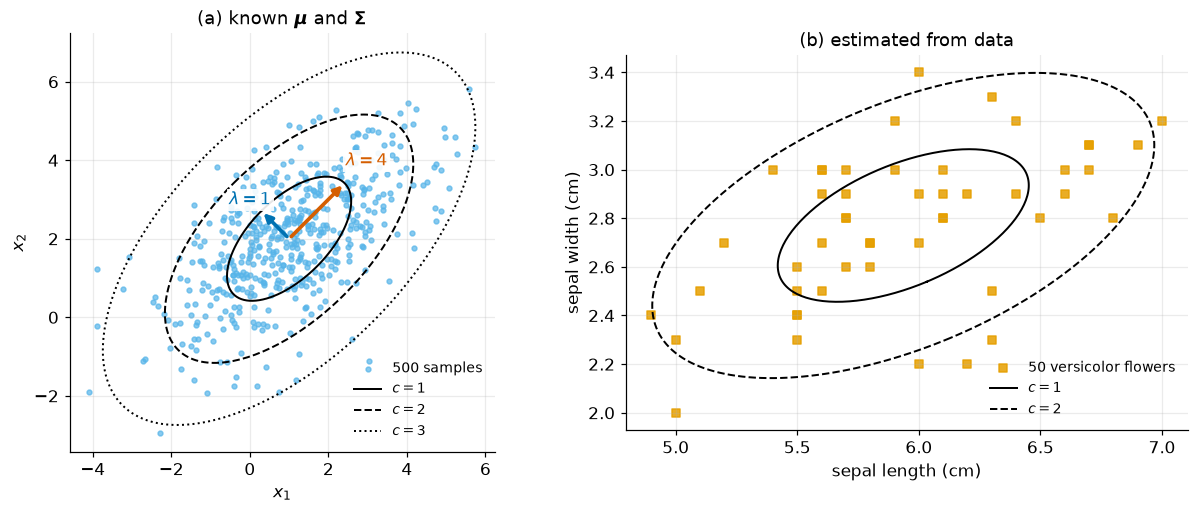

In [33]:
# Figure 2.4 — the multivariate Gaussian and its ellipses
def ellipse(mu, Sigma, c, m=200):
    """Points of the ellipse {x : (x - mu)^T Sigma^{-1} (x - mu) = c^2}."""
    lam, Q = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2 * np.pi, m)
    circle = np.vstack([np.cos(t), np.sin(t)])                 # shape (2, m)
    return (mu[:, None] + c * Q @ (np.sqrt(lam)[:, None] * circle)).T


def figure_2_4():
    import matplotlib.pyplot as plt
    from sklearn.datasets import load_iris

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

    # (a) a Gaussian with known parameters
    mu = np.array([1.0, 2.0]); Sigma = np.array([[2.5, 1.5], [1.5, 2.5]])
    sample = np.random.default_rng(SEED).multivariate_normal(mu, Sigma, size=500)
    ax = axes[0]
    ax.scatter(sample[:, 0], sample[:, 1], s=10, color=SKY, alpha=0.7, label="500 samples")
    for c, ls in zip((1, 2, 3), ("-", "--", ":")):
        e = ellipse(mu, Sigma, c)
        ax.plot(e[:, 0], e[:, 1], color="black", linestyle=ls, linewidth=1.3, label=f"$c = {c}$")
    lam, Q = np.linalg.eigh(Sigma)
    for i, color in ((1, VERMILION), (0, BLUE)):                # eigh sorts the eigenvalues in increasing order
        tip = mu + Q[:, i] * np.sqrt(lam[i])
        ax.annotate("", xy=tip, xytext=mu, arrowprops={"arrowstyle": "-|>", "color": color, "lw": 2.4}, zorder=5)
        label_pos = mu + 1.4 * Q[:, i] * np.sqrt(lam[i])
        ax.text(label_pos[0], label_pos[1], rf"$\lambda={lam[i]:.0f}$", color=color, fontsize=11, ha="center", va="center",
                zorder=6, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9, "pad": 1.5})
    ax.set(xlabel="$x_1$", ylabel="$x_2$", title="(a) known $\\boldsymbol{\\mu}$ and $\\boldsymbol{\\Sigma}$")
    ax.set_aspect("equal"); ax.legend(frameon=False, loc="lower right", fontsize=9)

    # (b) the same picture estimated from real data
    iris = load_iris()
    pts = iris.data[iris.target == 1][:, :2]                    # versicolor: sepal length and width
    mu_hat, Sigma_hat = pts.mean(axis=0), np.cov(pts, rowvar=False)
    ax = axes[1]
    ax.scatter(pts[:, 0], pts[:, 1], s=22, color=ORANGE, marker="s", alpha=0.85, label="50 versicolor flowers")
    for c, ls in zip((1, 2), ("-", "--")):
        e = ellipse(mu_hat, Sigma_hat, c)
        ax.plot(e[:, 0], e[:, 1], color="black", linestyle=ls, linewidth=1.3, label=f"$c = {c}$")
    ax.set(xlabel="sepal length (cm)", ylabel="sepal width (cm)", title="(b) estimated from data")
    ax.set_aspect("equal"); ax.legend(frameon=False, loc="lower right", fontsize=9)

    fig.tight_layout()
    plt.show()

figure_2_4()

The arrows in panel (a) point along the eigenvectors, and their lengths are $\sqrt{\lambda_i}$, the standard deviation along each direction. The ellipses with $c = 1, 2, 3$ are the sets at "1, 2, 3 Mahalanobis standard deviations" from the center. In two dimensions, the probability that a Gaussian sample falls inside the ellipse of parameter $c$ is $1 - e^{-c^2/2}$, which gives 39%, 86%, and 99% for $c = 1, 2, 3$ (compare with 68%, 95%, 99.7% in one dimension). The sample confirms it:

In [34]:
mu_a = np.array([1.0, 2.0]); Sigma_a = np.array([[2.5, 1.5], [1.5, 2.5]])
sample = np.random.default_rng(SEED).multivariate_normal(mu_a, Sigma_a, size=100_000)

diff = sample - mu_a
mahalanobis2 = np.einsum("ij,jk,ik->i", diff, np.linalg.inv(Sigma_a), diff)   # (x-mu)^T Sigma^{-1} (x-mu), row by row
print("sample mean:", sample.mean(axis=0).round(3), "| sample covariance:\n", np.cov(sample, rowvar=False).round(3))
for c in (1, 2, 3):
    print(f"c = {c}: fraction inside the ellipse = {(mahalanobis2 <= c**2).mean():.4f}   theory 1 - exp(-c^2/2) = {1 - np.exp(-c**2 / 2):.4f}")

sample mean: [1.003 2.004] | sample covariance:
 [[2.498 1.488]
 [1.488 2.506]]
c = 1: fraction inside the ellipse = 0.3927   theory 1 - exp(-c^2/2) = 0.3935
c = 2: fraction inside the ellipse = 0.8627   theory 1 - exp(-c^2/2) = 0.8647
c = 3: fraction inside the ellipse = 0.9889   theory 1 - exp(-c^2/2) = 0.9889


### 2.6.6 The law of large numbers and the central limit theorem

Let $X_1, X_2, \dots, X_n$ be independent draws from the same distribution, with mean $\mu$ and variance $\sigma^2$, and let $\bar{X}_n = \frac{1}{n}\sum_{i=1}^n X_i$ be their average. Two theorems describe what happens as $n$ grows.

- **Law of large numbers (LLN).** $\bar{X}_n \to \mu$. Averages settle down on the expectation. By linearity, $\mathbb{E}[\bar X_n] = \mu$, and by independence $\operatorname{Var}(\bar X_n) = \sigma^2/n$, so the typical error of the sample mean, its **standard error**, is $\sigma/\sqrt{n}$.
- **Central limit theorem (CLT).** The *shape* of the fluctuations becomes Gaussian, whatever the original distribution: the standardized average $\sqrt{n}\,(\bar X_n - \mu)/\sigma$ approaches the standard Gaussian $\mathcal{N}(0, 1)$.

Together they say that the error of an empirical average decreases like $1/\sqrt{n}$ and is approximately Gaussian: **to halve the error you need four times as much data**. They are the reason why empirical risk (an average) is a good estimate of expected risk, and why test-set accuracies come with error bars. The figure shows both: on the left, five independent running averages of coin flips with $p = 0.3$; on the right, the standardized average of $n$ draws from the (very asymmetric) exponential distribution with $\lambda = 1$, for three values of $n$.

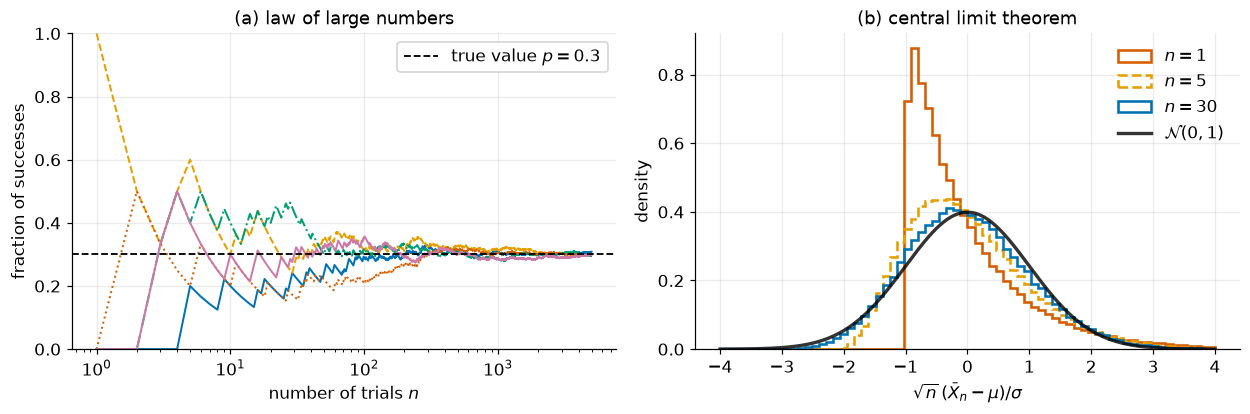

In [35]:
# Figure 2.5 — law of large numbers and central limit theorem
def figure_2_5():
    import matplotlib.pyplot as plt
    from scipy import stats

    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

    # (a) LLN: running averages of Bernoulli(0.3) trials
    p, n = 0.3, 5000
    flips = rng.random((5, n)) < p
    running = np.cumsum(flips, axis=1) / np.arange(1, n + 1)
    ax = axes[0]
    for r, color, ls in zip(running, [BLUE, ORANGE, GREEN, VERMILION, PURPLE], ["-", "--", "-.", ":", "-"]):
        ax.plot(np.arange(1, n + 1), r, color=color, linestyle=ls, linewidth=1.3)
    ax.axhline(p, color="black", linewidth=1.2, linestyle="--", label="true value $p = 0.3$")
    ax.set(xscale="log", xlabel="number of trials $n$", ylabel="fraction of successes",
           title="(a) law of large numbers", ylim=(0, 1))
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)

    # (b) CLT: standardized averages of exponential(1) samples (mean 1, standard deviation 1)
    draws = rng.exponential(1.0, size=(100_000, 30))
    ax = axes[1]
    for n_, color, ls in [(1, VERMILION, "-"), (5, ORANGE, "--"), (30, BLUE, "-")]:
        zs = (draws[:, :n_].mean(axis=1) - 1.0) * np.sqrt(n_)
        ax.hist(zs, bins=70, range=(-4, 4), density=True, histtype="step", color=color, linestyle=ls,
                linewidth=1.7, label=f"$n = {n_}$")
    grid = np.linspace(-4, 4, 400)
    ax.plot(grid, stats.norm.pdf(grid), color="black", linewidth=2.2, alpha=0.8, label=r"$\mathcal{N}(0, 1)$")
    ax.set(xlabel=r"$\sqrt{n}\,(\bar{X}_n - \mu)/\sigma$", ylabel="density", title="(b) central limit theorem")
    ax.legend(frameon=False)

    fig.tight_layout()
    plt.show()

figure_2_5()

Panel (a): with few trials the running averages differ a lot from one run to the next, and then all of them squeeze towards 0.3. Panel (b): for $n = 1$ the histogram is the original, strongly skewed exponential (shifted and rescaled); for $n = 5$ it is already much more symmetric, and for $n = 30$ it is hard to distinguish from the Gaussian. We can measure the convergence instead of eyeballing it, with the **skewness** (zero for a symmetric distribution; for the average of $n$ exponentials it equals $2/\sqrt{n}$) and the **Kolmogorov–Smirnov distance**, the largest vertical gap between the empirical CDF and the Gaussian CDF.

In [36]:
rng = np.random.default_rng(SEED)
draws = rng.exponential(1.0, size=(100_000, 100))     # 100,000 repetitions of "draw 100 numbers"

print(f"{'n':>4} {'skewness':>9} {'theory 2/sqrt(n)':>17} {'KS distance':>12} {'std of mean':>12} {'sigma/sqrt(n)':>14}")
for n in (1, 2, 5, 10, 30, 100):
    means = draws[:, :n].mean(axis=1)
    z = (means - 1.0) * np.sqrt(n)                    # standardized: mu = sigma = 1
    print(f"{n:>4} {stats.skew(means):>9.3f} {2 / np.sqrt(n):>17.3f} {stats.kstest(z, 'norm').statistic:>12.4f} "
          f"{means.std():>12.4f} {1 / np.sqrt(n):>14.4f}")

   n  skewness  theory 2/sqrt(n)  KS distance  std of mean  sigma/sqrt(n)
   1     1.990             2.000       0.1587       0.9990         1.0000
   2     1.420             1.414       0.0967       0.7038         0.7071
   5     0.889             0.894       0.0608       0.4473         0.4472
  10     0.638             0.632       0.0406       0.3172         0.3162
  30     0.358             0.365       0.0255       0.1824         0.1826


 100     0.203             0.200       0.0161       0.0995         0.1000


Both the skewness and the distance to the Gaussian shrink steadily with $n$, and the spread of the sample mean tracks $\sigma/\sqrt{n}$: the standard error predicted by the LLN. The LLN and the CLT have conditions (independent draws with finite variance), and we will meet situations, such as **dependent** samples or **heavy-tailed** data, where they fail. It is one of the reasons for which the test set must be independent of the training set.

### 2.6.7 Maximum likelihood estimation

How do we choose the parameters of a probabilistic model from data? Suppose that the data $x_1, \dots, x_n$ are independent draws from a distribution $p(x;\theta)$ with unknown parameter $\theta$. The **likelihood** of $\theta$ is the probability (density) that the model assigns to the observed data, viewed as a function of $\theta$:
$$
L(\theta) = \prod_{i=1}^{n} p(x_i; \theta).
$$
The **maximum likelihood estimate** (MLE) is the parameter value that makes the data most probable, $\hat\theta = \operatorname{argmax}_\theta L(\theta)$. In practice we maximize the **log-likelihood** $\ell(\theta) = \sum_{i=1}^n \log p(x_i;\theta)$, for two reasons. The logarithm is increasing, so it has the same maximizer; and it turns a product of many small numbers, which underflows (trap 4 of Section 2.3.8), into a sum. Equivalently, we *minimize* the **negative log-likelihood**, which will play the role of the loss function in many methods.

**Example 1: Bernoulli.** We observe $k$ successes in $n$ independent trials, each with success probability $p$. Then $\ell(p) = k\log p + (n - k)\log(1 - p)$, and
$$
\ell'(p) = \frac{k}{p} - \frac{n - k}{1 - p} = 0 \;\Longrightarrow\; k(1 - p) = (n - k)p \;\Longrightarrow\; \hat p = \frac{k}{n}.
$$
Since $\ell''(p) = -k/p^2 - (n - k)/(1 - p)^2 < 0$, this is a maximum: the MLE is the observed fraction of successes.

**Example 2: Gaussian.** For $x_i \sim \mathcal{N}(\mu, \sigma^2)$,
$$
\ell(\mu, \sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(x_i - \mu)^2 .
$$
Setting $\partial\ell/\partial\mu = \frac{1}{\sigma^2}\sum_i (x_i - \mu) = 0$ gives $\hat\mu = \bar x$, the sample mean. Setting $\partial\ell/\partial\sigma^2 = -\frac{n}{2\sigma^2} + \frac{1}{2\sigma^4}\sum_i (x_i - \hat\mu)^2 = 0$ gives
$$
\hat\mu = \frac{1}{n}\sum_{i=1}^n x_i, \qquad \hat\sigma^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \hat\mu)^2 .
$$
The MLE of the variance divides by $n$ and is slightly **biased**: its expected value is $\frac{n-1}{n}\sigma^2$, because the data points are closer to their own mean $\bar x$ than to the true $\mu$. Dividing by $n - 1$ instead gives the *unbiased* estimator used for $\hat{\boldsymbol\Sigma}$ above. The simulation below shows the effect for samples of size $n = 5$.

In [37]:
rng = np.random.default_rng(SEED)
samples = rng.normal(loc=0.0, scale=1.0, size=(200_000, 5))        # 200,000 samples of size 5, true variance 1

print("average of the variance estimates over the 200,000 samples (true value: 1)")
print(f"  dividing by n     (MLE, ddof=0): {samples.var(axis=1, ddof=0).mean():.4f}   (theory (n-1)/n = {4/5})")
print(f"  dividing by n - 1 (unbiased, ddof=1): {samples.var(axis=1, ddof=1).mean():.4f}")

average of the variance estimates over the 200,000 samples (true value: 1)
  dividing by n     (MLE, ddof=0): 0.8013   (theory (n-1)/n = 0.8)
  dividing by n - 1 (unbiased, ddof=1): 1.0017


:::{admonition} Pitfall
:class: warning
**`ddof` differs between libraries.** `np.var` and `np.std` divide by $n$ by default (`ddof=0`), as does scikit-learn's `StandardScaler`; pandas' `Series.std()`, `DataFrame.describe()`, and `np.cov` divide by $n - 1$ (`ddof=1`). For large $n$ the difference is negligible, but for a handful of samples it is not, and it explains tiny discrepancies when you compare two computations of "the same" standard deviation.
:::

### Worked example 2.5 — the bias of a coin

We flip a coin 10 times and see 7 heads. By Example 1, $\hat p = 7/10 = 0.7$. The code checks this by evaluating the log-likelihood on a grid of values of $p$, and compares with a larger experiment, 70 heads in 100 flips, that gives the same estimate with more evidence. The second part of Figure 2.6 fits a Gaussian to the alcohol content of the 178 wines.

In [38]:
p_grid = np.linspace(0.001, 0.999, 999)

def bernoulli_loglik(p, k, n):
    return k * np.log(p) + (n - k) * np.log(1 - p)

for k, n in [(7, 10), (70, 100)]:
    ll = bernoulli_loglik(p_grid, k, n)
    print(f"{k} heads in {n} flips: maximizer on the grid = {p_grid[ll.argmax()]:.3f} (formula k/n = {k / n})"
          f" | log-likelihood drops by {ll.max() - bernoulli_loglik(0.5, k, n):.2f} at p = 0.5")

alcohol = load_wine(as_frame=True).frame["alcohol"].to_numpy()
print(f"\nGaussian MLE for alcohol: mu = {alcohol.mean():.4f}, sigma = {alcohol.std(ddof=0):.4f} (unbiased: {alcohol.std(ddof=1):.4f})")

7 heads in 10 flips: maximizer on the grid = 0.700 (formula k/n = 0.7) | log-likelihood drops by 0.82 at p = 0.5
70 heads in 100 flips: maximizer on the grid = 0.700 (formula k/n = 0.7) | log-likelihood drops by 8.23 at p = 0.5

Gaussian MLE for alcohol: mu = 13.0006, sigma = 0.8095 (unbiased: 0.8118)


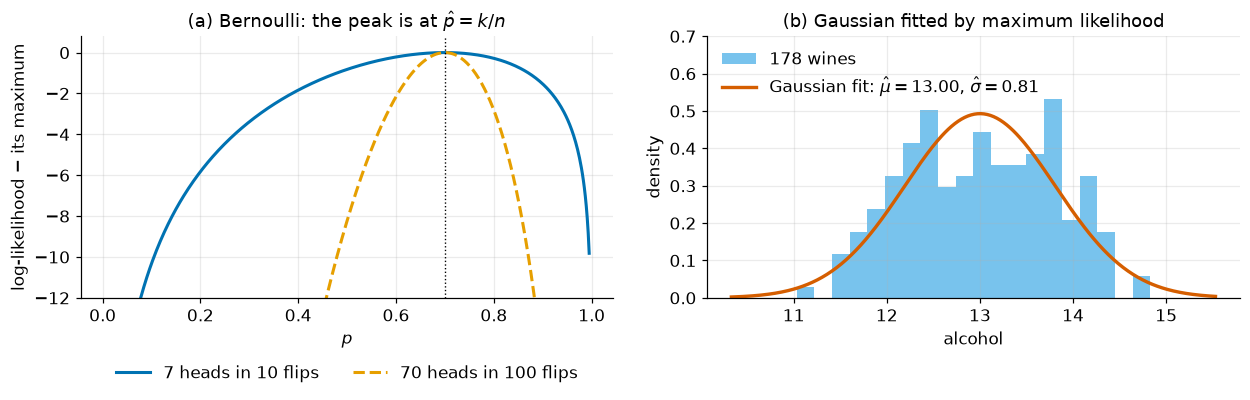

In [39]:
# Figure 2.6 — maximum likelihood in pictures
def figure_2_6():
    import matplotlib.pyplot as plt
    from scipy import stats
    from sklearn.datasets import load_wine

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))

    ax = axes[0]
    p = np.linspace(0.005, 0.995, 500)
    for (k, n), color, ls in zip([(7, 10), (70, 100)], [BLUE, ORANGE], ["-", "--"]):
        ll = k * np.log(p) + (n - k) * np.log(1 - p)
        ax.plot(p, ll - ll.max(), color=color, linestyle=ls, linewidth=2, label=f"{k} heads in {n} flips")
    ax.axvline(0.7, color="black", linewidth=0.9, linestyle=":")
    ax.set(xlabel="$p$", ylabel=r"log-likelihood $-$ its maximum", ylim=(-12, 0.8),
           title=r"(a) Bernoulli: the peak is at $\hat{p}=k/n$")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)

    ax = axes[1]
    a = load_wine(as_frame=True).frame["alcohol"].to_numpy()
    mu_hat, sigma_hat = a.mean(), a.std()
    ax.hist(a, bins=20, density=True, color=SKY, alpha=0.8, label="178 wines")
    xs = np.linspace(a.min() - 0.7, a.max() + 0.7, 300)
    ax.plot(xs, stats.norm.pdf(xs, mu_hat, sigma_hat), color=VERMILION, linewidth=2.2,
            label=rf"Gaussian fit: $\hat\mu={mu_hat:.2f}$, $\hat\sigma={sigma_hat:.2f}$")
    ax.set(xlabel="alcohol", ylabel="density", title="(b) Gaussian fitted by maximum likelihood", ylim=(0, 0.7))
    ax.legend(loc="upper left", frameon=False)

    fig.tight_layout()
    plt.show()

figure_2_6()

In panel (a), both curves peak at $\hat p = 0.7$, but with 100 flips the peak is much sharper: the data rule out values of $p$ far from 0.7 much more strongly. The *curvature* of the log-likelihood at its maximum measures how much information the data contain. In panel (b), a single Gaussian is a reasonable first description of the alcohol content, although the histogram is a bit flatter than the bell curve (the wines come from three different cultivars, so the data are really a mixture; Chapter 12 will treat that).

### Why least squares? The Gaussian-noise view

In Chapter 1 we chose the squared loss because it is convenient and geometric. Maximum likelihood gives it a probabilistic reason. Suppose that the targets are generated as
$$
y_i = f(\mathbf{x}_i; \mathbf{w}) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2) \text{ independent},
$$
that is, $y_i \mid \mathbf{x}_i \sim \mathcal{N}\big(f(\mathbf{x}_i;\mathbf{w}),\,\sigma^2\big)$. The log-likelihood of the whole training set is, by the Gaussian formula above,
$$
\ell(\mathbf{w}, \sigma^2) = -\frac{n}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^n \big(y_i - f(\mathbf{x}_i;\mathbf{w})\big)^2 .
$$
For any fixed $\sigma$, the weights that maximize $\ell$ are exactly those that **minimize the sum of squared errors**. Setting the derivative with respect to $\sigma^2$ to zero as before gives $\hat\sigma^2 = \frac{1}{n}\sum_i (y_i - f(\mathbf{x}_i;\hat{\mathbf{w}}))^2$: the MLE of the noise variance is the **mean squared error** of the fit.

:::{admonition} Key idea
:class: tip
**Choosing a loss is choosing a noise model.** Squared loss corresponds to Gaussian noise. Other assumptions give other losses: Laplace-distributed noise gives the absolute loss (compare with Exercise 1.5), and, in Chapter 6, a Bernoulli model for the labels will give the cross-entropy loss of logistic regression. When someone asks "why this loss?", the answer is often "because of this assumption on the data".
:::

We can check the claim numerically on the Diabetes data of Chapter 1. We minimize the negative log-likelihood with a general-purpose optimizer, without using the formulas of least squares, and compare with `np.linalg.lstsq`.

In [40]:
from scipy import optimize
from sklearn.datasets import load_diabetes

diab = load_diabetes(as_frame=True, scaled=False).frame
bmi, progression = diab["bmi"].to_numpy(), diab["target"].to_numpy()
A = np.column_stack([np.ones_like(bmi), bmi])                  # design matrix with intercept

w_lstsq = np.linalg.lstsq(A, progression, rcond=None)[0]

def negative_log_likelihood(params):
    w, log_sigma = params[:2], params[2]                        # optimize log(sigma) so that sigma stays positive
    sigma = np.exp(log_sigma)
    residuals = progression - A @ w
    return len(progression) * np.log(sigma * np.sqrt(2 * np.pi)) + np.sum(residuals ** 2) / (2 * sigma ** 2)

result = optimize.minimize(negative_log_likelihood, x0=np.array([0.0, 0.0, np.log(50.0)]),
                           method="Nelder-Mead", options={"maxiter": 5000, "xatol": 1e-9, "fatol": 1e-9})
rmse = np.sqrt(np.mean((progression - A @ w_lstsq) ** 2))
print("least squares weights   :", w_lstsq.round(4))
print("maximum likelihood w    :", result.x[:2].round(4))
print(f"MLE of sigma = {np.exp(result.x[2]):.4f} | root mean squared error of the least-squares fit = {rmse:.4f}")

least squares weights   : [-117.7734   10.2331]
maximum likelihood w    : [-117.7734   10.2331]
MLE of sigma = 62.3735 | root mean squared error of the least-squares fit = 62.3735


The two sets of weights coincide, and the maximum likelihood estimate of $\sigma$ equals the root mean squared error, as the derivation predicts. We have not yet *used* this: in Chapter 3 we study when empirical risk minimization works, in Chapter 6 we add regularization, and the probabilistic view above will explain what regularization means.

## 2.7 Data preprocessing: from raw tables to model-ready matrices

Raw data are rarely ready for a learning algorithm. Features live on different scales, some distributions are very skewed, entries are missing, and some columns contain categories instead of numbers. **Preprocessing** is the set of transformations that fix this, and it is often where most of the practical gains (and most of the bugs) are.

Every method has implicit assumptions. Distance-based methods (k-NN, clustering) assume that distances are meaningful across features; gradient-based methods train faster when the features have similar scales; regularized linear models penalize the weights, so the units of the features change the solution; and almost nothing tolerates a `NaN`. Preprocessing makes the data fit those assumptions.

:::{admonition} Key idea
:class: tip
**The golden rule of preprocessing.** Anything that *learns something from the data* (a mean, a standard deviation, the value used to fill a gap, the list of categories) must be learned from the **training set only**, and then *applied* unchanged to the validation and test sets. Otherwise information from the test set leaks into the training process (the data leakage of Chapter 1) and the test score becomes optimistic. In scikit-learn the tool that enforces the rule is the **`Pipeline`**: every `fit` call sees only the training data.
:::

### 2.7.1 Feature scales

On the Wine data, `proline` has a standard deviation of about 315 and `hue` of about 0.23 (Section 2.4). What does this do to a method that measures distances? In k-NN the distance between two wines is $\lVert\mathbf{x} - \mathbf{x}'\rVert_2 = \sqrt{\sum_j (x_j - x'_j)^2}$, so each feature contributes in proportion to its squared difference. Let us measure how much of the squared distance, on average over all pairs, each feature accounts for.

In [41]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

wine_X, wine_y = load_wine(return_X_y=True)
wine_features = load_wine().feature_names

def distance_shares(M):
    """Average share of the squared Euclidean distance (over all pairs of samples) due to each feature."""
    per_feature = ((M[:, None, :] - M[None, :, :]) ** 2).mean(axis=(0, 1))     # broadcasting, shape (d,)
    return pd.Series(per_feature / per_feature.sum(), index=wine_features)

raw_shares = distance_shares(wine_X)
std_shares = distance_shares(StandardScaler().fit_transform(wine_X))
print("raw data, the three largest shares of the squared distance:")
for name, share in raw_shares.sort_values(ascending=False).head(3).items():
    print(f"  {name:<20} {100 * share:6.2f} %")
print(f"\nafter standardization every feature contributes {100 * std_shares.min():.1f}% to {100 * std_shares.max():.1f}%")

raw data, the three largest shares of the squared distance:
  proline               99.77 %
  magnesium              0.21 %
  alcalinity_of_ash      0.01 %

after standardization every feature contributes 7.7% to 7.7%


On the raw data, `proline` alone accounts for about 99.8% of the squared distance: the other twelve features are practically ignored by the distance, however informative they might be. After standardization every feature contributes equally. Here is what this does to the accuracy of 5-nearest-neighbors on this data set. Since the result depends on the random split, we repeat the experiment on 30 different splits and report the mean and standard deviation of the test accuracy (Chapter 5 will present more refined ways to do this).

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

def knn_accuracy(make_model, seeds=range(30)):
    """Test accuracy of a model on Wine, over several random 70/30 stratified splits."""
    scores = []
    for seed in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(wine_X, wine_y, test_size=0.3, stratify=wine_y, random_state=seed)
        scores.append(make_model().fit(X_tr, y_tr).score(X_te, y_te))
    return np.mean(scores), np.std(scores)

models = {
    "no scaling":      lambda: KNeighborsClassifier(n_neighbors=5),
    "standardization": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "min-max":         lambda: make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=5)),
    "robust":          lambda: make_pipeline(RobustScaler(), KNeighborsClassifier(n_neighbors=5)),
}
for name, make_model in models.items():
    mean_acc, std_acc = knn_accuracy(make_model)
    print(f"{name:<16} test accuracy = {mean_acc:.3f} +/- {std_acc:.3f}")

no scaling       test accuracy = 0.699 +/- 0.049


standardization  test accuracy = 0.960 +/- 0.020
min-max          test accuracy = 0.960 +/- 0.017


robust           test accuracy = 0.947 +/- 0.023


The jump from about 0.70 to about 0.96 comes from a single line of preprocessing, with no change to the algorithm. This is typical: **scaling is the first thing to try when a distance-based or gradient-based method behaves strangely.** (Methods based on trees, Chapter 11, are insensitive to monotone rescaling of the features and do not need it. And the least-squares predictions of Chapter 1 do not change either, because rescaling a column of $\mathbf{X}$ only rescales the corresponding weight: but regularized and gradient-based versions of linear models do care.)

The three scalers used above are, for a feature with values $x$:

| Scaler | Formula | Result | Sensitive to outliers? |
|---|---|---|---|
| **Standardization** (`StandardScaler`) | $z = \dfrac{x - \hat\mu}{\hat\sigma}$ | mean 0, standard deviation 1 | yes (through $\hat\mu$ and $\hat\sigma$) |
| **Min-max** (`MinMaxScaler`) | $x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$ | values in $[0, 1]$ | very (the extremes define the range) |
| **Robust** (`RobustScaler`) | $x'' = \dfrac{x - \operatorname{median}}{Q_3 - Q_1}$ | median 0, interquartile range 1 | little |

Standardization is the default. Min-max scaling is natural for bounded inputs such as pixel intensities. The robust scaler is the choice when a few extreme values would otherwise dominate. Remember that these scalers change the **units**, not the **shape** of the distribution of a feature: if a feature is skewed, it stays skewed. For that we need a *transformation*, which is the topic of the next figure.

The code below shows the golden rule in action. The scaler learns $\hat\mu$ and $\hat\sigma$ from the training set; the **test** set is transformed with the *training* values, so its mean is not exactly 0, and that is correct: the test set represents data that we have not seen.

In [43]:
X_tr, X_te, y_tr, y_te = train_test_split(wine_X, wine_y, test_size=0.3, stratify=wine_y, random_state=SEED)

scaler = StandardScaler().fit(X_tr)                  # learn the mean and std from the TRAINING set only
Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)

print("training set, means of the first 4 columns:", Z_tr.mean(axis=0)[:4].round(3), "(zero by construction)")
print("test set,     means of the first 4 columns:", Z_te.mean(axis=0)[:4].round(3), "(not zero, and that is fine)")
print("scaler.mean_ and scale_ are the training mean and std:",
      np.allclose(scaler.mean_, X_tr.mean(axis=0)), np.allclose(scaler.scale_, X_tr.std(axis=0)))

training set, means of the first 4 columns: [0. 0. 0. 0.] (zero by construction)
test set,     means of the first 4 columns: [ 0.182  0.154  0.037 -0.17 ] (not zero, and that is fine)
scaler.mean_ and scale_ are the training mean and std: True True


### Figure 2.7 — scalers change units, transformations change shape

The top row shows the `magnesium` feature, which has a few high values, after each of the three scalers. The four histograms have **the same shape**: only the horizontal axis changes. Look at the ranges: with min-max scaling, the bulk of the data is squeezed into the interval from about 0.2 to 0.5 because of the maximum, while the robust scaler centers the median at 0 and gives the central half of the data a width of 1. The bottom row shows the skewed feature `proline` under three **transformations**: the logarithm, the Yeo-Johnson power transform (a data-driven family that works for any sign), and the quantile transform that maps the data to a Gaussian. These *do* change the shape: the skewness, which is 0 for a symmetric distribution, drops from 0.76 to almost 0.

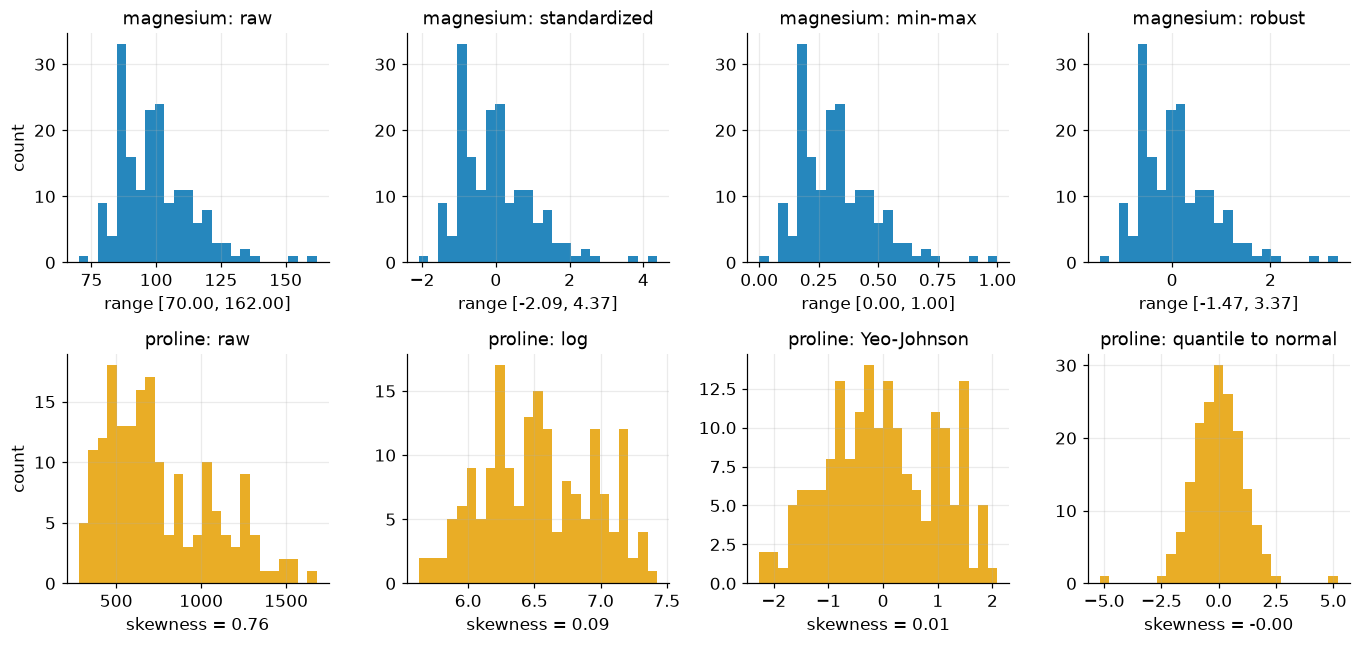

In [44]:
# Figure 2.7 — scalers change units, transformations change shape
def figure_2_7():
    import matplotlib.pyplot as plt
    from scipy import stats
    from sklearn.datasets import load_wine
    from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                       PowerTransformer, QuantileTransformer)

    data = load_wine(as_frame=True).frame
    mg, pr = data[["magnesium"]].to_numpy(), data[["proline"]].to_numpy()

    top = [("raw", mg), ("standardized", StandardScaler().fit_transform(mg)),
           ("min-max", MinMaxScaler().fit_transform(mg)), ("robust", RobustScaler().fit_transform(mg))]
    bottom = [("raw", pr), ("log", np.log(pr)), ("Yeo-Johnson", PowerTransformer().fit_transform(pr)),
              ("quantile to normal", QuantileTransformer(n_quantiles=len(pr), output_distribution="normal").fit_transform(pr))]

    fig, axes = plt.subplots(2, 4, figsize=(12.5, 6.0))
    for ax, (name, v) in zip(axes[0], top):
        ax.hist(v.ravel(), bins=25, color=BLUE, alpha=0.85)
        ax.set(title=f"magnesium: {name}", xlabel=f"range [{v.min():.2f}, {v.max():.2f}]")
    for ax, (name, v) in zip(axes[1], bottom):
        ax.hist(v.ravel(), bins=25, color=ORANGE, alpha=0.85)
        ax.set(title=f"proline: {name}", xlabel=f"skewness = {stats.skew(v.ravel()):.2f}")
    axes[0, 0].set_ylabel("count"); axes[1, 0].set_ylabel("count")
    fig.tight_layout()
    plt.show()

figure_2_7()

**When to transform.** Take the logarithm of positive quantities that span orders of magnitude or act multiplicatively (incomes, prices, concentrations, counts); `np.log1p(x)` $= \log(1 + x)$ is safe when zeros occur. Transform the *features* freely; if you transform the *target*, remember to transform the predictions back before computing errors in the original units.

### 2.7.2 Outliers

An **outlier** is an observation far from the bulk of the data. It may be an error (a misplaced decimal point), or a genuine rare event, and the two call for different treatments. A common screening rule flags the values outside the interval $[\,Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}\,]$, where $Q_1$ and $Q_3$ are the first and third quartiles and $\mathrm{IQR} = Q_3 - Q_1$: it is the rule that draws the circles in the box plots of Figure 2.2.

In [45]:
magnesium = load_wine(as_frame=True).frame["magnesium"].to_numpy()
q1, q3 = np.percentile(magnesium, [25, 75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (magnesium < low) | (magnesium > high)

print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr}  ->  acceptable range [{low}, {high}]")
print("flagged values:", magnesium[is_outlier], "| they are", is_outlier.sum(), "of", len(magnesium))
print(f"mean/std with all data: {magnesium.mean():.2f} / {magnesium.std():.2f} | without the flagged values: "
      f"{magnesium[~is_outlier].mean():.2f} / {magnesium[~is_outlier].std():.2f}")
print(f"median/IQR with all data: {np.median(magnesium):.1f} / {iqr:.1f} | without the flagged values: "
      f"{np.median(magnesium[~is_outlier]):.1f} / {np.subtract(*np.percentile(magnesium[~is_outlier], [75, 25])):.1f}")
winsorized = np.clip(magnesium, low, high)               # winsorizing: pull extreme values to the boundary
print("after clipping, the largest value is:", winsorized.max())

Q1 = 88.0, Q3 = 107.0, IQR = 19.0  ->  acceptable range [59.5, 135.5]
flagged values: [151. 139. 136. 162.] | they are 4 of 178
mean/std with all data: 99.74 / 14.24 | without the flagged values: 98.66 / 12.35
median/IQR with all data: 98.0 / 19.0 | without the flagged values: 97.5 / 18.8
after clipping, the largest value is: 135.5


The mean and the standard deviation move noticeably when four values are removed, while the median and the interquartile range hardly change: this is why the robust scaler uses the latter. **Do not delete outliers automatically.** First look at them, and ask whether they are errors; if they are real, they are exactly the cases on which the model will be tested. Possible actions, in order of preference: keep them and use a robust method; clip (winsorize) them to the boundary, as in the last line above; or, when you are sure they are errors, remove or correct them and document it.

### 2.7.3 Missing values

Real data sets have holes: a sensor failed, a patient skipped a test, a form field was left blank. Most algorithms cannot handle a `NaN`, so we must either **drop** rows or columns, or **impute** (fill in) the missing entries. How serious the problem is depends on *why* the data are missing:

- **MCAR** (missing completely at random): the missingness has nothing to do with the data, for example a random sensor failure. This is the easiest case.
- **MAR** (missing at random): the missingness depends on *other observed* variables, for example older patients skip a certain test more often.
- **MNAR** (missing not at random): the missingness depends on the missing value itself, for example people with very high incomes refuse to report them. This is the hardest case, and no imputation method can fully repair it.

Real data sets contain no ground truth for the missing entries, so how can we compare imputation strategies? We can do an experiment: take a **complete** data set, remove entries at random (we know what they were), impute, and measure the error. The Diabetes data has no missing values, so we remove 10% of the entries of its nine numerical features, completely at random. This is an artificial MCAR scenario, and it is the *friendliest* one: real data are usually harder.

In [46]:
from sklearn.impute import SimpleImputer, KNNImputer

raw = load_diabetes(as_frame=True, scaled=False).frame
num_cols = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
X_true = raw[num_cols].to_numpy()

rng = np.random.default_rng(SEED)
mask = rng.random(X_true.shape) < 0.10               # True where the entry is removed
X_miss = np.where(mask, np.nan, X_true)

complete_rows = (~mask.any(axis=1)).sum()
print(f"removed {mask.mean():.1%} of the {mask.size} entries")
print(f"rows without any missing value: {complete_rows} of {len(X_true)} ({complete_rows / len(X_true):.0%});"
      f" expected: {0.9 ** len(num_cols):.0%}")

removed 10.1% of the 3978 entries
rows without any missing value: 166 of 442 (38%); expected: 39%


Only 38% of the rows are complete. Deleting every row that has at least one missing entry (`dropna`), which is the default behavior of many tools, would throw away **62% of the data**, although only 10% of the entries are missing: with many features, almost every row has a hole somewhere. Imputation keeps the rows. The simplest imputation replaces a missing entry with the mean (or the median) of the observed values of that feature. A more refined one, the **k-nearest-neighbors imputer**, fills the entry with the average of that feature over the $k$ most similar rows, where similarity is measured on the features that are observed in both rows; it can exploit the correlations between features (in this data set, `s1` and `s2` have a correlation of 0.90). We measure the error in **standardized units**, so that a value of 1 means "as large as the standard deviation of the feature".

In [47]:
# Standardize with the observed values only (StandardScaler ignores the NaN when fitting)
scaler = StandardScaler().fit(X_miss)
Z_miss, Z_true = scaler.transform(X_miss), scaler.transform(X_true)

imputers = {
    "mean":            SimpleImputer(strategy="mean"),
    "median":          SimpleImputer(strategy="median"),
    "k-NN, k = 1":     KNNImputer(n_neighbors=1),
    "k-NN, k = 5":     KNNImputer(n_neighbors=5),
    "k-NN, k = 20":    KNNImputer(n_neighbors=20),
}
print("root mean squared error on the removed entries, in standard deviations:")
for name, imputer in imputers.items():
    Z_filled = imputer.fit_transform(Z_miss)
    rmse_imp = np.sqrt(np.mean((Z_filled - Z_true)[mask] ** 2))
    print(f"  {name:<14} {rmse_imp:.3f}")

root mean squared error on the removed entries, in standard deviations:
  mean           1.014
  median         1.021
  k-NN, k = 1    1.098
  k-NN, k = 5    0.803
  k-NN, k = 20   0.750


Mean and median imputation have an error of about 1: they predict the "typical" value and ignore everything else we know about the row. The k-NN imputer does better when $k$ is large enough, because it uses the correlated features, but with $k = 1$ it is *worse* than the mean: a single neighbor is too noisy. The choice of $k$ is a hyperparameter, to be tuned like any other (Chapter 5).

Two further remarks. First, sometimes the fact that a value is missing is itself informative (a patient without a test result might be healthier); `SimpleImputer(add_indicator=True)` appends a 0/1 column for each feature with missing values, so that the model can use this information. Second, the imputer is **fitted** (it learns means or neighbors), so it belongs in the pipeline, as we do in Section 2.7.5.

### 2.7.4 Categorical features

Features such as a color, a country, or a blood type take a finite number of **categories** and have no numeric meaning. If a column contains the codes 1, 2, 3 for three categories, a linear model would treat "3" as three times "1", which is nonsense unless the categories are naturally ordered. Two encodings are standard.

- **Ordinal encoding** maps ordered categories to integers (`low < medium < high` becomes 0, 1, 2). Use it only when the order is meaningful.
- **One-hot encoding** creates one 0/1 column per category (the "dummy variables"): exactly one of them is 1 in each row. It makes no assumption about order.

The Diabetes data has no categorical column, so we create two, purely for demonstration: the `sex` column holds the codes 1 and 2 (their meaning is not documented in the data set, and we simply treat them as labels), and we cut `age` into three groups. The second is a *loss* of information, which we would not do in a real analysis, but it gives us an ordered categorical feature.

In [48]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

age_group = pd.cut(raw["age"], bins=[0, 40, 55, 100], labels=["young", "middle", "senior"])
print("people per age group:", age_group.value_counts().reindex(["young", "middle", "senior"]).to_dict())

onehot = OneHotEncoder(sparse_output=False).fit(age_group.to_frame())          # input: a DataFrame with one column
print("\none-hot columns:", list(onehot.get_feature_names_out()))
print("first 3 rows:\n", onehot.transform(age_group.to_frame())[:3])

ordinal = OrdinalEncoder(categories=[["young", "middle", "senior"]])             # we state the order explicitly
print("ordinal codes of the first 3 rows:", ordinal.fit_transform(age_group.to_frame())[:3].ravel())

people per age group: {'young': 122, 'middle': 177, 'senior': 143}

one-hot columns: ['age_middle', 'age_senior', 'age_young']
first 3 rows:
 [[0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]
ordinal codes of the first 3 rows: [2. 1. 2.]


**The dummy-variable trap.** The three one-hot columns always add up to 1, which is the same as the intercept column of ones. A linear model with an intercept *and* all three dummies has linearly dependent columns: this is exactly the situation of Exercise 1.10, in which $\mathbf{X}^\top\mathbf{X}$ is singular. The remedy is to drop one category (`OneHotEncoder(drop="first")`): the dropped category becomes the reference level, absorbed by the intercept.

In [49]:
dummies = pd.get_dummies(age_group).to_numpy(dtype=float)                  # all three levels
design_all = np.column_stack([np.ones(len(dummies)), dummies])             # intercept + 3 dummies
design_drop = design_all[:, :3]                                            # intercept + 2 dummies
print(f"intercept + 3 dummies: shape {design_all.shape}, rank {np.linalg.matrix_rank(design_all)}  -> columns are dependent")
print(f"intercept + 2 dummies: shape {design_drop.shape}, rank {np.linalg.matrix_rank(design_drop)}  -> full column rank")

intercept + 3 dummies: shape (442, 4), rank 3  -> columns are dependent
intercept + 2 dummies: shape (442, 3), rank 3  -> full column rank


Two more practical points. A categorical column with thousands of categories (a postal code, a user identifier) cannot be one-hot encoded naively, because it creates thousands of columns; there are special techniques for such cases, which we will not need in this book. And when a category appears in the test set that was not in the training set, `OneHotEncoder(handle_unknown="ignore")` encodes it as a row of zeros instead of raising an error.

### 2.7.5 Putting it all together: `ColumnTransformer` and `Pipeline`

We now assemble the pieces in one object. A **`ColumnTransformer`** applies different transformations to different groups of columns: numerical columns are scaled and imputed, categorical ones are one-hot encoded. A **`Pipeline`** chains this preprocessing with a model. The resulting object has the usual `fit` and `predict` methods, and `fit` learns everything (means, standard deviations, imputation values, categories, weights) from the training set only.

We use the Diabetes data with the two categorical columns of the previous section, with the same 10% of missing entries in the numerical columns, and a plain linear regression as the model. To judge the different treatments of the missing values fairly we repeat the experiment on 30 random 70/30 splits and report the mean and standard deviation of the $R^2$ on the test set; as a reference we also train on the original complete data.

In [50]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Data frame with two categorical columns, complete and with the missing entries of the previous section
X_all = raw.drop(columns="target").copy()
y_diab = raw["target"]
X_all["sex"] = X_all["sex"].astype(int).astype(str)                       # the codes 1 and 2 as labels
X_all["age_group"] = age_group.astype(str)
cat_cols = ["sex", "age_group"]
X_holes = X_all.copy()
X_holes[num_cols] = X_holes[num_cols].mask(mask)                         # NaN where `mask` is True

def make_model(imputer):
    # Scale first (NaN are ignored when fitting and kept in the output), then impute on comparable scales
    numeric = make_pipeline(StandardScaler(), imputer)
    prep = ColumnTransformer([("num", numeric, num_cols),
                              ("cat", OneHotEncoder(drop="first"), cat_cols)])
    return Pipeline([("prep", prep), ("regression", LinearRegression())])

print(make_model(SimpleImputer()))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('standardscaler',
                                                                   StandardScaler()),
                                                                  ('simpleimputer',
                                                                   SimpleImputer())]),
                                                  ['age', 'bmi', 'bp', 's1',
                                                   's2', 's3', 's4', 's5',
                                                   's6']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'age_group'])])),
                ('regression', LinearRegression())])


In [51]:
def repeated_r2(X, y, build, seeds=range(30), drop_incomplete_rows=False):
    """Test R^2 of a pipeline over several random splits."""
    scores = []
    for seed in seeds:
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=seed)
        if drop_incomplete_rows:                                          # use only the complete training rows
            keep = ~X_tr[num_cols].isna().any(axis=1)
            X_tr, y_tr = X_tr[keep], y_tr[keep]
        scores.append(build().fit(X_tr, y_tr).score(X_te, y_te))
    return np.mean(scores), np.std(scores)

experiments = {
    "complete data (reference)":      (X_all,   lambda: make_model(SimpleImputer()),                False),
    "mean imputation":                (X_holes, lambda: make_model(SimpleImputer()),                False),
    "median imputation":              (X_holes, lambda: make_model(SimpleImputer(strategy="median")), False),
    "mean + missing indicators":      (X_holes, lambda: make_model(SimpleImputer(add_indicator=True)), False),
    "k-NN imputation (k = 5)":        (X_holes, lambda: make_model(KNNImputer(n_neighbors=5)),     False),
    "drop incomplete training rows":  (X_holes, lambda: make_model(SimpleImputer()),                True),
}
results = pd.DataFrame(
    [(name, *repeated_r2(X, y_diab, build, drop_incomplete_rows=drop)) for name, (X, build, drop) in experiments.items()],
    columns=["treatment of the missing values", "mean test R2", "std over splits"]).set_index("treatment of the missing values")
results.round(3)

,mean test R2,std over splits
treatment of the missing values,,
complete data (reference),0.470,0.049
mean imputation,0.425,0.048
median imputation,0.426,0.048
mean + missing indicators,0.404,0.061
k-NN imputation (k = 5),0.447,0.044
drop incomplete training rows,0.307,0.084


In [52]:
# How many complete rows does the "drop" strategy have to train on? (the training set has 309 rows)
complete_in_train = [
    (~X_holes[num_cols].isna().any(axis=1).to_numpy()[train_test_split(np.arange(len(X_holes)), test_size=0.3, random_state=seed)[0]]).sum()
    for seed in range(30)
]
print(f"complete rows in a training set: {np.mean(complete_in_train):.0f} on average (out of 309)")

complete rows in a training set: 116 on average (out of 309)


All treatments lose against the complete data, since the information is really gone, but they lose by very different amounts. Mean and median imputation cost about 0.045 of $R^2$; k-NN imputation recovers about half of that loss; adding missing-value indicators *hurts* here (nine more noisy columns for a training set of only 309 samples); and dropping incomplete rows is by far the worst, with an $R^2$ near 0.31 and a much larger variability between splits, because it trains on about 116 rows instead of 309. The ranking is a property of this data set and this model, but the lesson is general: **do not throw data away if you can avoid it, and compare the treatments with the same protocol.**

The whole procedure is a single object. We can inspect the names of the columns that the model receives, and apply it to new data with `predict`, without any manual step:

In [53]:
model = make_model(KNNImputer(n_neighbors=5))
X_tr, X_te, y_tr, y_te = train_test_split(X_holes, y_diab, test_size=0.3, random_state=SEED)
model.fit(X_tr, y_tr)
print("features seen by the regression:", list(model.named_steps["prep"].get_feature_names_out()))
print("learned weights:", model.named_steps["regression"].coef_.round(2))
print("test R2 with this split:", round(model.score(X_te, y_te), 3))

features seen by the regression: ['num__age', 'num__bmi', 'num__bp', 'num__s1', 'num__s2', 'num__s3', 'num__s4', 'num__s5', 'num__s6', 'cat__sex_2', 'cat__age_group_senior', 'cat__age_group_young']
learned weights: [ -0.88  25.38  17.51  -2.83 -11.26  -9.97  12.88  15.7    5.22 -25.41
   9.59  -1.35]
test R2 with this split: 0.473


:::{admonition} Pitfall
:class: warning
**Never call `fit` or `fit_transform` on the test set**, and never preprocess the whole data set *before* splitting it. If you standardize `X` with `StandardScaler().fit_transform(X)` and only afterwards split into train and test, the mean and standard deviation of the test samples have influenced the training features. The effect is often small, but with imputers, feature selection, or target-dependent encodings it can be large, and it is invisible: your test score simply comes out better than the real performance. Put every learned step in a `Pipeline` and the problem cannot arise.
:::

### A checklist for preprocessing

1. **Look at the data first**: shapes, types, `describe()`, histograms, missing values (Sections 2.4 and 2.5).
2. **Split before you fit anything**; keep the test set untouched until the end.
3. **Decide per column**: numerical (scale, transform if skewed, impute), categorical (one-hot or ordinal), or to be discarded (identifiers, constant columns).
4. **Wrap the steps in a `ColumnTransformer` and a `Pipeline`**, so that `fit` uses the training data only and the very same transformations are applied at prediction time.
5. **Compare alternatives with the same protocol**, repeating over several splits when the data set is small.
6. **Keep the raw data unchanged** and write the preprocessing as code: it must be reproducible.

## 2.8 Summary

- **NumPy** arrays have a **shape** and a **dtype**; slicing gives **views**, masks and fancy indexing give copies. `axis=k` is the axis that disappears in a reduction. **Vectorize** instead of looping, and use **broadcasting** (compare shapes from the right: equal or 1) with care: always check shapes, especially $(n,)$ against $(n, 1)$.
- **Numerical traps**: do not compare floats with `==`; avoid cancellation (use `np.var`); subtract the maximum before exponentiating (stable softmax); prefer log-probabilities to probabilities; solve systems with `np.linalg.solve` or `lstsq`, never with the explicit inverse; use `eigh` for symmetric matrices.
- **pandas** DataFrames label the rows and columns: `loc` (labels, end included), `iloc` (positions), Boolean masks, `groupby`, `describe`, `corr`. Use `.loc` for assignments and `.to_numpy()` to get arrays.
- **Matplotlib**: use `fig, ax = plt.subplots()` and the methods of the Axes. Honest figures have labeled axes, color-blind-safe colors with a second encoding, and show the spread.
- **Probability**: Bayes' rule $\mathbb{P}(A\mid B) = \mathbb{P}(B\mid A)\mathbb{P}(A)/\mathbb{P}(B)$ (mind the prior!); $\mathbb{E}$ is linear, $\operatorname{Var}(X) = \mathbb{E}[X^2] - \mathbb{E}[X]^2$; the covariance matrix $\boldsymbol\Sigma$ is symmetric positive semidefinite, with eigenvectors that give the directions and eigenvalues that give the variances of the cloud; the **multivariate Gaussian** has elliptical level sets; the **LLN** and the **CLT** say that averages converge to the mean at rate $1/\sqrt{n}$ with Gaussian fluctuations.
- **Maximum likelihood** maximizes $\sum_i \log p(x_i;\theta)$: it gives $\hat p = k/n$ for a Bernoulli and $\hat\mu = \bar x$, $\hat\sigma^2 = \frac1n\sum(x_i-\bar x)^2$ for a Gaussian. **Least squares is maximum likelihood under Gaussian noise**: a loss encodes a noise model.
- **Preprocessing**: scale features (standardization by default), transform skewed ones, treat outliers with care, impute rather than drop, encode categories (one-hot, dropping one level when there is an intercept), and put everything in a **Pipeline** that is fitted on the training data only.

### Data sources

- *Iris*: R. A. Fisher, "The use of multiple measurements in taxonomic problems", *Annals of Eugenics* 7(2), 179–188 (1936). Bundled with scikit-learn.
- *Wine*: M. Forina et al., *PARVUS: An Extendible Package for Data Exploration, Classification and Correlation*, Institute of Pharmaceutical and Food Analysis and Technologies, Genoa (1991). Obtained from the UCI Machine Learning Repository and bundled with scikit-learn.
- *Diabetes*: B. Efron, T. Hastie, I. Johnstone and R. Tibshirani, "Least Angle Regression", *Annals of Statistics* (with discussion), 407–499 (2004). Bundled with scikit-learn. The missing values and the categorical columns used in Section 2.7 were created artificially from the complete data, as explained there.
- *Breast Cancer Wisconsin (Diagnostic)*: W. N. Street, W. H. Wolberg and O. L. Mangasarian, "Nuclear feature extraction for breast tumor diagnosis", *IS&T/SPIE 1993 International Symposium on Electronic Imaging: Science and Technology*, volume 1905, 861–870 (1993). Bundled with scikit-learn.
- The screening-test numbers of Worked example 2.3 are illustrative.

### Further reading

- C. R. Harris et al., "Array programming with NumPy", *Nature* 585, 357–362 (2020).
- W. McKinney, *Python for Data Analysis*, 3rd ed., O'Reilly, 2022 (pandas and NumPy in depth, by the author of pandas).
- J. D. Hunter, "Matplotlib: A 2D graphics environment", *Computing in Science & Engineering* 9(3), 90–95 (2007).
- L. Wasserman, *All of Statistics*, Springer, 2004 (probability and maximum likelihood, concise and rigorous).
- D. P. Bertsekas and J. N. Tsitsiklis, *Introduction to Probability*, 2nd ed., Athena Scientific, 2008 (Bayes' rule, random variables, limit theorems).
- R. J. A. Little and D. B. Rubin, *Statistical Analysis with Missing Data*, 3rd ed., Wiley, 2019 (MCAR, MAR, MNAR).
- N. J. Higham, *Accuracy and Stability of Numerical Algorithms*, 2nd ed., SIAM, 2002 (floating-point arithmetic).

## 2.9 Exercises

Difficulty: ★ warm-up, ★★ core, ★★★ challenge. Try each exercise before reading the hint; solutions and detailed outlines are in [Appendix C](../appendices/appendix_c_solutions.ipynb).

### Manual (analytical) exercises

**Exercise 2.1 ★ — Shapes and broadcasting.** Let `A` have shape $(5, 3)$, `v` shape $(3,)$, `c` shape $(5, 1)$ and `r` shape $(1, 3)$. (a) For each of the following expressions say whether it is valid and, if so, what its shape is: `A + v`, `A + c`, `v + c`, `A @ v`, `A @ c`, `c @ r`, `r @ A`. (b) Given `X` of shape $(n, d)$, `w` of shape $(d,)$ and `y` of shape $(n,)$, write the mean squared error of the linear model in one NumPy expression and give the shape of every intermediate result. (c) If `y` has shape $(n,)$ and `y_hat` has shape $(n, 1)$, what is the shape of `y - y_hat`, and what number does `np.mean((y - y_hat) ** 2)` compute? Check your answer on the data of the Pitfall in Section 2.3.6.

*Hint for (c).* The result contains the entry $(y_i - \hat y_j)^2$ for **every pair** $(i, j)$. Expand the square and average over $i$ and $j$.

**Exercise 2.2 ★ — Counting heads.** Let $X$ be the number of heads in three flips of a fair coin. (a) Write the probability mass function of $X$. (b) Compute $\mathbb{E}[X]$ and $\operatorname{Var}(X)$ from the definitions, and check them against the formulas $np$ and $np(1-p)$. (c) Let $Z = 2X - 3$. Compute $\mathbb{E}[Z]$ and $\operatorname{Var}(Z)$. What does $Z$ represent?

*Hint.* The pmf of a Binomial$(3, \tfrac12)$ is $\binom{3}{k}/8$. For (c) use $\mathbb{E}[aX + b] = a\,\mathbb{E}[X] + b$ and $\operatorname{Var}(aX + b) = a^2\operatorname{Var}(X)$.

**Exercise 2.3 ★★ — A spam filter by Bayes.** 40% of the e-mails that arrive are spam. The word "free" appears in 60% of the spam e-mails and in 5% of the legitimate ones ("ham"). (a) What is the probability that an e-mail is spam, given that it contains "free"? (b) The word "winner" appears in 30% of the spam and in 2% of the ham. Assuming that, within each class, the two words occur independently, what is the probability that an e-mail containing both words is spam? (c) Which assumption did you use in (b), and what can go wrong if it is false?

*Hint.* Use Bayes' rule with the law of total probability in the denominator, as in Worked example 2.3. For (b), multiply the likelihoods of the two words inside each class.

**Exercise 2.4 ★★ — Maximum likelihood for the exponential distribution.** Let $x_1, \dots, x_n$ be independent draws from the exponential distribution with density $f(x;\lambda) = \lambda e^{-\lambda x}$ for $x \ge 0$. (a) Write the log-likelihood $\ell(\lambda)$ and find the maximum likelihood estimate $\hat\lambda$. (b) Verify with the second derivative that it is a maximum. (c) Compute $\hat\lambda$ for the data $0.5,\ 1.5,\ 1.0,\ 2.0$, and say what the mean of the fitted distribution is.

*Hint.* $\log f(x_i;\lambda) = \log\lambda - \lambda x_i$. The mean of the exponential distribution is $1/\lambda$ (see the table in Section 2.6.4).

**Exercise 2.5 ★★★ — Covariance matrices and whitening.** Let $\mathbf{x} \in \mathbb{R}^2$ be a random vector with $\mathbb{E}[\mathbf{x}] = \mathbf{0}$ and covariance matrix $\boldsymbol{\Sigma} = \begin{pmatrix} 5 & 2 \\ 2 & 2 \end{pmatrix}$. (a) Find the eigenvalues and orthonormal eigenvectors of $\boldsymbol{\Sigma}$. What are the variances of $\mathbf{x}$ along those two directions? (b) Prove that for any matrix $\mathbf{A}$, the vector $\mathbf{z} = \mathbf{A}\mathbf{x}$ has covariance $\mathbf{A}\boldsymbol{\Sigma}\mathbf{A}^\top$, and that $\boldsymbol{\Sigma}$ is positive semidefinite. (c) Find a matrix $\mathbf{A}$ such that $\operatorname{Cov}(\mathbf{A}\mathbf{x}) = \mathbf{I}$ (a **whitening** transformation) and verify it. (d) If $\mathbf{x}$ is Gaussian, what is the probability that $\mathbf{x}^\top\boldsymbol{\Sigma}^{-1}\mathbf{x} \le 4$?

*Hint.* For (b), $\operatorname{Cov}(\mathbf{z}) = \mathbb{E}[\mathbf{A}\mathbf{x}\mathbf{x}^\top\mathbf{A}^\top]$ and $\mathbf{v}^\top\boldsymbol\Sigma\mathbf{v} = \operatorname{Var}(\mathbf{v}^\top\mathbf{x})$. For (c), write $\boldsymbol\Sigma = \mathbf{Q}\boldsymbol\Lambda\mathbf{Q}^\top$ and try $\mathbf{A} = \boldsymbol\Lambda^{-1/2}\mathbf{Q}^\top$. For (d), use the formula of Section 2.6.5.

### Python (computational) exercises

**Exercise 2.6 ★ — Array warm-up on Iris.** (a) Compute the mean of each of the four features for each of the three species with a Boolean mask and a loop over the species, and check the result against `pandas`' `groupby`. (b) Standardize the columns of the Iris data matrix with broadcasting (no scikit-learn) and verify that the means are 0 and the standard deviations 1. (c) Show that the covariance matrix of the standardized data (computed with `ddof=0`) is equal to the **correlation matrix** of the original data.

*Hint.* `np.cov(Z, rowvar=False, ddof=0)` and `np.corrcoef(X, rowvar=False)`. Why does standardizing turn covariances into correlations?

**Exercise 2.7 ★★ — A k-NN classifier without loops over the samples.** Write a function `knn_predict(X_train, y_train, X_test, k)` that returns the predicted labels for the rows of `X_test`, using the Gram-matrix identity of Worked example 2.1 to compute all distances at once, `np.argpartition` (or `np.argsort`) to find the $k$ nearest neighbors, and a majority vote. Test it on the standardized Wine data, with 30 random stratified 70/30 splits and $k = 5$, and compare the predictions with those of `KNeighborsClassifier`. How often do they agree? What is the mean test accuracy?

*Hint.* The distances from the test points to the training points form a matrix of shape `(n_test, n_train)`. For the vote you may loop over the test points, or use `np.apply_along_axis` with `np.bincount(...).argmax()`.

**Exercise 2.8 ★★ — Exploring the Breast Cancer data with pandas.** Load the Breast Cancer Wisconsin data with `load_breast_cancer(as_frame=True)`. (a) How many samples are there in each class, and what do 0 and 1 mean? (b) For each of the 30 features compute the **standardized difference** between the classes, $d_j = \lvert \bar x_{j,0} - \bar x_{j,1}\rvert / s_{p,j}$, where $s_{p,j}$ is the pooled standard deviation, $s_p^2 = \frac{(n_0 - 1)s_0^2 + (n_1 - 1)s_1^2}{n_0 + n_1 - 2}$. Which five features separate the classes best, and which three worst? (c) Draw a scatter plot of the two best features, with different colors and markers per class. (d) Compute the correlation between `mean radius` and `mean perimeter` and comment: what does it suggest about using both features in a linear model?

*Hint.* `df.groupby("target").mean()`, `Series.sort_values()`. A large $d_j$ means that the class means are far apart compared with the spread inside a class.

**Exercise 2.9 ★★★ — How fast is the central limit theorem?** Repeat the experiment of Section 2.6.6 for the **uniform** distribution on $[0, 1]$ (mean $1/2$, variance $1/12$) with 200,000 repetitions. For $n = 1, 2, 3, 5, 10$, compute the Kolmogorov-Smirnov distance between the standardized sample mean and the standard Gaussian, and plot it against $n$ on a log-log scale together with the same quantity for the exponential distribution. Estimate the slope of each curve with `np.polyfit` on the logarithms. Which distribution converges faster, and why? (Hint: compare the skewness of the two distributions.)

*Hint.* Standardized mean: $\sqrt{n}\,(\bar X_n - \mu)/\sigma$ with $\sigma = \sqrt{1/12}$. For the exponential with $\lambda = 1$ the skewness is 2 and for the uniform it is 0. A theory of the error terms (Edgeworth expansions) says that the leading error is proportional to the skewness divided by $\sqrt{n}$.

**Exercise 2.10 ★★★ — A preprocessing laboratory, and a leak.** (a) On the Wine data, compare no scaling, standardization, min-max scaling and robust scaling for $k$-NN with $k \in \{1, 5, 15\}$, with 30 stratified 70/30 splits, and present the mean test accuracies in a table. (b) Now commit the error of Section 2.7 *on purpose*: standardize the **whole** data set first, then split. Compare, for the same splits, with the correct pipeline. Is the difference systematic? (c) Leakage is much more dangerous when the preprocessing step uses the **labels**. Generate $n = 60$ samples of 2000 independent Gaussian features and **random** labels (so that there is nothing to learn), and repeat 30 times: select the 10 features with the highest `f_classif` score (`SelectKBest`) *on the whole data set*, then split, fit 5-NN, and compute the test accuracy. Compare with the correct procedure, in which the selection is part of a `Pipeline` fitted on the training set only. What accuracy should one expect on pure noise, and what do you observe?

*Hint.* For (a) and (b) reuse the function `knn_accuracy` of Section 2.7.1 in a modified form. For (c): `SelectKBest(f_classif, k=10)`, `make_pipeline(SelectKBest(...), KNeighborsClassifier(5))`.

## What comes next

In **Chapter 3** we turn the informal ideas of Chapter 1 (expected risk, empirical risk, generalization) into a precise theory, using the probability of this chapter: the expectation and the law of large numbers will be the main tools. From **Chapter 4** on, we study learning methods one at a time. We begin with the simplest one, k-nearest neighbors, which you already know how to implement with the vectorized distances of this chapter, and we use it to understand the central trade-off between bias and variance.